# Modele Audio

## Reconnaissance des émotions à partir de l’audio

L’objectif est de prédire l’émotion d’un extrait de film qu'à partir
de sa bande sonore.

Nous commençons par vérifier les données et examiner quelques
caractéristiques sur l’ensemble d’apprentissage.

Nous conservons la partition commune du projet. Tous les extraits
d’un même film appartiennent au même ensemble.


## Modèles testés

Nous avons testé les modèles suivants, dans cet ordre :

- **eGeMAPS + régression logistique**
- **Référence majoritaire**
- **eGeMAPS + NN**
- **YAMNet + NN**
- **YAMNet + eGeMAPS + NN**
- **AST fine-tuné avec classifieur neuronal**
- **Wav2vec2 MSP + régression logistique**
- **Wav2vec2 MSP + NN**
- **Wav2vec2 MSP fine-tune + NN**
- **HuBERT + NN**
- **Emotion2vec+ Large + NN**
- **MFCC + CNN**

Le modèle retenu est **wav2vec2 MSP avec fine-tuning**, car il obtient le meilleur F1 macro sur dev.

### Installation des bibliothèques


In [ ]:
# Exécuter cette cellule avant les imports, puis redémarrer le noyau
# si l'installation demande un redémarrage.
%pip install -q "opensmile==2.6.0" "transformers==4.57.1" accelerate tensorflow-hub tf-keras librosa soundfile safetensors joblib

import os
os.environ["USE_TF"] = "0"  # Transformers sera utilisé avec PyTorch.


In [ ]:
from pathlib import Path
from datetime import datetime
import psutil

fichier_suivi = Path(
    "/content/drive/MyDrive/SID/derniere_cellule.txt"
)

def suivre_execution(evenement):
    debut_cellule = "\n".join(
        evenement.raw_cell.strip().splitlines()[:5]
    )

    ram_disponible = psutil.virtual_memory().available / 1024**3

    fichier_suivi.write_text(
        f"Date : {datetime.now()}\n"
        f"RAM disponible avant la cellule : {ram_disponible:.2f} Gio\n\n"
        f"{debut_cellule}",
        encoding="utf-8"
    )

get_ipython().events.register("pre_run_cell", suivre_execution)

print("Suivi activé.")

Suivi activé.


## 1. Accès aux données

Nous retrouvons l’archive, la partition commune et les sauvegardes du projet.


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

dossier_projet = Path("/content/drive/MyDrive/SID")
chemin_zip = dossier_projet / "PROJET_SID_2026.zip"
chemin_partition = dossier_projet / "Group 1.csv"
dossier_audio_temporaire = Path("/content/audio_ast_16000Hz")

assert chemin_zip.is_file(), f"Archive introuvable : {chemin_zip}"
assert chemin_partition.is_file(), f"Partition introuvable : {chemin_partition}"
print("Dossier du projet :", dossier_projet)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dossier du projet : /content/drive/MyDrive/SID


### Réutilisation des sauvegardes

Les fonctions ci-dessous servent uniquement trouver les modeles deja fait pour ne pas les entrainer de nouveau.


In [ ]:
import numpy as np

import json
import joblib

# False : charger les modèles présents ; entraîner seulement ceux qui manquent.
# True : refaire tous les entraînements en conservant les mêmes réglages.
reentrainer = False

dossier_modeles = dossier_projet / "modeles_audio"
dossier_caracteristiques = dossier_projet / "caracteristiques_audio"
dossier_modeles.mkdir(parents=True, exist_ok=True)
dossier_caracteristiques.mkdir(parents=True, exist_ok=True)


def verifier_caracteristiques(table, extraits, colonnes):
    assert table.index.is_unique
    assert set(table.index) == set(extraits["video_id"])
    assert table.columns.tolist() == list(colonnes)
    assert np.isfinite(table.to_numpy()).all()
    return table.loc[extraits["video_id"]].copy()


def fichier_poids(dossier):
    for nom in ["model.safetensors", "pytorch_model.bin"]:
        chemin = dossier / nom
        if chemin.is_file():
            return chemin
    return None


def trouver_modele(nom):
    dossier = dossier_modeles / nom
    if fichier_poids(dossier / "meilleur") is not None:
        return dossier / "meilleur"

    # Les anciens checkpoints peuvent encore contenir un chemin Colab.
    # On retrouve le dossier local en gardant son nom checkpoint-XXXX.
    candidats = []
    for chemin_etat in dossier.rglob("trainer_state.json"):
        etat = json.loads(chemin_etat.read_text(encoding="utf-8"))
        meilleur = etat.get("best_model_checkpoint")
        score = etat.get("best_metric")
        if meilleur is None or score is None:
            continue
        checkpoint = chemin_etat.parent.parent / Path(meilleur).name
        if fichier_poids(checkpoint) is not None:
            candidats.append((float(score), etat.get("global_step", 0), checkpoint))
    if candidats:
        return max(candidats, key=lambda ligne: (ligne[0], ligne[1]))[2]
    return None


def charger_poids(modele, dossier):
    import torch
    from safetensors.torch import load_file

    chemin = fichier_poids(dossier)
    if chemin is None:
        raise FileNotFoundError(f"Poids absents : {dossier}")
    if chemin.suffix == ".safetensors":
        poids = load_file(str(chemin), device="cpu")
    else:
        poids = torch.load(chemin, map_location="cpu", weights_only=True)
    modele.load_state_dict(poids, strict=True)
    modele.eval()
    return modele


def verifier_ordre_sauvegarde(dossier):
    # Vérifier les métadonnées quand elles accompagnent l'ancienne sauvegarde.
    for chemin in [dossier / "parametres.json",
                   dossier_modeles / "parametres_modeles_audio.json"]:
        if chemin.is_file():
            parametres = json.loads(chemin.read_text(encoding="utf-8"))
            if "ordre_emotions" in parametres:
                assert parametres["ordre_emotions"] == ordre_emotions


def sauvegarder_keras(modele, standardisation, nom, colonnes):
    dossier = dossier_modeles / nom
    dossier.mkdir(parents=True, exist_ok=True)
    modele.save(dossier / "classifieur.keras")
    joblib.dump(standardisation, dossier / "standardisation.joblib")
    parametres = {"ordre_emotions": ordre_emotions, "colonnes": list(colonnes)}
    (dossier / "parametres.json").write_text(
        json.dumps(parametres, ensure_ascii=False, indent=2), encoding="utf-8"
    )


def keras_disponible(nom):
    dossier = dossier_modeles / nom
    return ((dossier / "classifieur.keras").is_file()
            and (dossier / "standardisation.joblib").is_file())


### 1.1. Vérification de la partition commune

Nous chargeons la partition et vérifions le nombre de films par ensemble
ainsi que l’absence d’identifiants répétés.


In [ ]:
import pandas as pd

# Charger la partition en conservant les zéros des identifiants
partition = pd.read_csv(
    chemin_partition,
    dtype={"film_id": str}
)

display(partition.head())

# Vérifier les identifiants et les effectifs
print("Nombre total de films :", len(partition))
print("Identifiants répétés :", partition["film_id"].duplicated().sum())

print("\nFilms par ensemble :")
print(partition["split"].value_counts().reindex(["train", "dev", "test"]))


,film_id,split
0,00000,test
1,00002,train
2,00003,test
3,00004,train
4,00005,train


Nombre total de films : 350
Identifiants répétés : 0

Films par ensemble :
split
train    250
dev       50
test      50
Name: count, dtype: int64


## 2. Construction de la table des extraits audio

Nous utilisons les annotations pour retrouver l’identifiant, l’émotion
et la durée de chaque extrait. Nous associerons ensuite chaque extrait
à l’ensemble de son film.


In [ ]:
import zipfile

# Lister les fichiers contenus dans l’archive
with zipfile.ZipFile(chemin_zip, "r") as archive:
    fichiers_archive = archive.namelist()

# Sélectionner les annotations JSON et conserver un ordre stable
chemins_annotations = sorted(
    chemin
    for chemin in fichiers_archive
    if chemin.startswith("PROJET_SID_2026/movie/annotation/")
    and chemin.endswith(".json")
)

print("Nombre d’annotations :", len(chemins_annotations))
print("Première annotation :", chemins_annotations[0])


Nombre d’annotations : 3088
Première annotation : PROJET_SID_2026/movie/annotation/00000/00000_clip_001.json


In [ ]:
import json

lignes_audio = []

# Lire les informations utiles de chaque annotation
with zipfile.ZipFile(chemin_zip, "r") as archive:
    for chemin in chemins_annotations:
        annotation = json.loads(archive.read(chemin))

        lignes_audio.append({
            "video_id": annotation["video_id"],
            "film_id": annotation["video_id"].split("_clip_")[0],
            "emotion": annotation["emotion"],
            "duration": annotation["duration"]
        })

donnees_audio = pd.DataFrame(lignes_audio)

# Retrouver l’ensemble attribué à chaque film
ensemble_par_film = partition.set_index("film_id")["split"]
donnees_audio["split"] = donnees_audio["film_id"].map(ensemble_par_film)

display(donnees_audio.head())

# Vérifier que chaque extrait possède un ensemble
print("Extraits sans ensemble :", donnees_audio["split"].isna().sum())

print("\nExtraits par ensemble :")
print(donnees_audio["split"].value_counts().reindex(["train", "dev", "test"]))


,video_id,film_id,emotion,duration,split
0,00000_clip_001,00000,anger,5.00,test
1,00000_clip_002,00000,anger,6.21,test
2,00000_clip_006,00000,contentment,7.38,test
3,00000_clip_009,00000,anger,4.80,test
4,00000_clip_012,00000,anger,5.25,test


Extraits sans ensemble : 0

Extraits par ensemble :
split
train    2207
dev       442
test      439
Name: count, dtype: int64


### 2.1. Vérification des fichiers audio

Nous verifions si tout les fichers audios sont present.


In [ ]:
# Construire le chemin de chaque fichier audio
donnees_audio["chemin_audio_zip"] = (
    "PROJET_SID_2026/movie/audio/"
    + donnees_audio["film_id"]
    + "/"
    + donnees_audio["video_id"]
    + ".mp3"
)

# Rechercher les fichiers attendus absents de l’archive
fichiers_presents = set(fichiers_archive)

audios_manquants = [
    chemin
    for chemin in donnees_audio["chemin_audio_zip"]
    if chemin not in fichiers_presents
]

print("Fichiers audio manquants :", len(audios_manquants))

if audios_manquants:
    print(audios_manquants[:5])


Fichiers audio manquants : 0


## 3. Observation d’un exemple audio

Nous écoutons ensuite un extrait d’apprentissage et observons son signal
pour mieux comprendre le contenu.

Cet exemple permet de vérifier la lecture du fichier.


In [ ]:
import io
import librosa

# Sélectionner les extraits d’apprentissage
audio_apprentissage = donnees_audio[
    donnees_audio["split"] == "train"
].copy()

# Choisir le premier extrait comme exemple
extrait_exemple = audio_apprentissage.iloc[0]

# Lire le fichier audio depuis l’archive
with zipfile.ZipFile(chemin_zip, "r") as archive:
    contenu_audio = io.BytesIO(
        archive.read(extrait_exemple["chemin_audio_zip"])
    )

signal_exemple, frequence_exemple = librosa.load(
    contenu_audio,
    sr=None,
    mono=True
)

print("Extrait :", extrait_exemple["video_id"])
print("Émotion :", extrait_exemple["emotion"])
print("Fréquence d’échantillonnage :", frequence_exemple, "Hz")
print("Durée décodée :", round(len(signal_exemple) / frequence_exemple, 2), "s")


Extrait : 00002_clip_004
Émotion : contentment
Fréquence d’échantillonnage : 44100 Hz
Durée décodée : 4.8 s


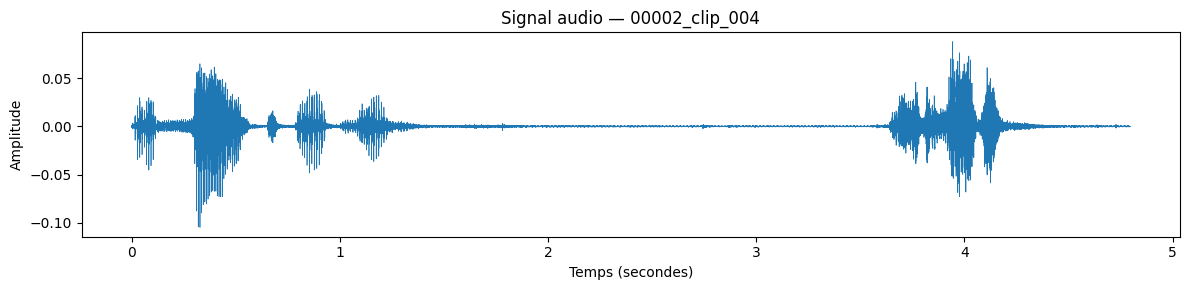

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

# Écouter le signal sans ajuster automatiquement son amplitude
display(Audio(
    signal_exemple,
    rate=frequence_exemple,
    normalize=False
))

# Calculer le temps correspondant à chaque échantillon
temps_exemple = np.arange(len(signal_exemple)) / frequence_exemple

# Afficher le signal audio
plt.figure(figsize=(12, 3))
plt.plot(temps_exemple, signal_exemple, linewidth=0.5)

plt.title(f"Signal audio — {extrait_exemple['video_id']}")
plt.xlabel("Temps (secondes)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()


L’extrait contient un court dialogue en anglais. Le signal présente
deux zones d’activité plus marquée.

L'exemple montre aussi des variations de niveau sonore au cours du temps.


## 4. Extraction des caractéristiques acoustiques

Nous utilisons openSMILE pour calculer les 88 caractéristiques eGeMAPSv02.
Elles décrivent la hauteur du son, le niveau sonore, le spectre et les
variations temporelles. Nous vérifions d'abord l'extraction sur un exemple.


In [ ]:
import opensmile

print("Version d’openSMILE :", opensmile.__version__)


Version d’openSMILE : 2.6.0


### 4.1. Extraction sur un exemple

Nous calculons les caractéristiques eGeMAPSv02 sur l’extrait observé.

Nous obtenons une ligne de 88 caractéristiques pour cet extrait.


In [ ]:
# Configurer l’extracteur
extracteur_audio = opensmile.Smile(
    feature_set=opensmile.FeatureSet.eGeMAPSv02,
    feature_level=opensmile.FeatureLevel.Functionals
)

# Calculer les caractéristiques de l’exemple
caracteristiques_exemple = extracteur_audio.process_signal(
    signal_exemple,
    frequence_exemple
)

print("Dimensions :", caracteristiques_exemple.shape)

# Afficher les 12 premières caractéristiques
display(caracteristiques_exemple.T.head(12))


Dimensions : (1, 88)


start,0 days
end,0 days 00:00:04.795986395
F0semitoneFrom27.5Hz_sma3nz_amean,33.314758
F0semitoneFrom27.5Hz_sma3nz_stddevNorm,0.364288
F0semitoneFrom27.5Hz_sma3nz_percentile20.0,21.776295
F0semitoneFrom27.5Hz_sma3nz_percentile50.0,32.743610
F0semitoneFrom27.5Hz_sma3nz_percentile80.0,44.811222
F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2,23.034927
F0semitoneFrom27.5Hz_sma3nz_meanRisingSlope,177.745209
F0semitoneFrom27.5Hz_sma3nz_stddevRisingSlope,46.112461
F0semitoneFrom27.5Hz_sma3nz_meanFallingSlope,227.553787


### 4.2. Extraction sur l’ensemble d’apprentissage

Nous reprenons les mêmes 88 mesures.


In [ ]:
chemin_caracteristiques_train = (
    dossier_caracteristiques / "egemapsv02_train_44100Hz.csv"
)


In [ ]:
if not chemin_caracteristiques_train.is_file():
    mesures_apprentissage = []

    with zipfile.ZipFile(chemin_zip, "r") as archive:
        for numero, extrait in enumerate(
            audio_apprentissage.itertuples(index=False),
            start=1
        ):
            # Lire le signal en mono à sa fréquence d’origine
            contenu = io.BytesIO(archive.read(extrait.chemin_audio_zip))
            signal, frequence = librosa.load(contenu, sr=None, mono=True)

            # Vérifier la cohérence des fréquences
            if frequence != frequence_exemple:
                raise ValueError(
                    f"Fréquence inattendue pour {extrait.video_id} : {frequence} Hz"
                )

            # Calculer les caractéristiques et conserver l’identifiant
            valeurs = extracteur_audio.process_signal(
                signal, frequence
            ).iloc[0].to_dict()

            valeurs["video_id"] = extrait.video_id
            mesures_apprentissage.append(valeurs)

            if numero % 250 == 0:
                print("Extraits traités :", numero)

    # Construire la table des caractéristiques
    caracteristiques_apprentissage = pd.DataFrame(
        mesures_apprentissage
    ).set_index("video_id")

    print("Dimensions finales :", caracteristiques_apprentissage.shape)
    caracteristiques_apprentissage.to_csv(chemin_caracteristiques_train, index_label="video_id")


### 4.3. Chargement des caractéristiques sauvegardées

Nous rechargeons les caractéristiques sauvegardées et vérifions
leur correspondance avec les extraits d’apprentissage.


In [ ]:
# Chemin du fichier sauvegardé lors de la première extraction
chemin_caracteristiques_train = (
    dossier_projet
    / "caracteristiques_audio"
    / "egemapsv02_train_44100Hz.csv"
)

# Charger les caractéristiques avec l’identifiant comme index
caracteristiques_apprentissage = pd.read_csv(
    chemin_caracteristiques_train,
    index_col="video_id"
)

# Vérifier les identifiants et les caractéristiques
assert caracteristiques_apprentissage.index.is_unique, \
    "Des identifiants sont répétés."

assert set(caracteristiques_apprentissage.index) == set(
    audio_apprentissage["video_id"]
), "Les extraits ne correspondent pas à l’apprentissage."

assert caracteristiques_apprentissage.columns.equals(
    caracteristiques_exemple.columns
), "Les colonnes ne correspondent pas à l’extraction actuelle."

# Ranger les lignes dans l’ordre des extraits d’apprentissage
caracteristiques_apprentissage = caracteristiques_apprentissage.loc[
    audio_apprentissage["video_id"]
]

print("Dimensions :", caracteristiques_apprentissage.shape)


Dimensions : (2207, 88)


## 5. Vérification des caractéristiques

Nous recherchons les valeurs manquantes ou infinies ainsi que
les caractéristiques constantes dans l’ensemble d’apprentissage.


In [ ]:
# Vérifier les valeurs numériques
print(
    "Valeurs manquantes :",
    caracteristiques_apprentissage.isna().sum().sum()
)

print(
    "Valeurs infinies :",
    np.isinf(caracteristiques_apprentissage.to_numpy()).sum()
)

# Compter les caractéristiques identiques pour tous les extraits
nombre_constantes = (
    caracteristiques_apprentissage.nunique(dropna=True) <= 1
).sum()

print("Caractéristiques constantes :", nombre_constantes)


Valeurs manquantes : 0
Valeurs infinies : 0
Caractéristiques constantes : 0


Aucune valeur manquante ou infinie et aucune caractéristique constante
n’ont été détectées.


## 6. Analyse exploratoire des caractéristiques audio

Nous comparons quelques caractéristiques entre les émotions pour observer
les différences et le recouvrement de leurs distributions.


In [ ]:
# Associer chaque identifiant à son émotion
emotions_apprentissage = audio_apprentissage.set_index("video_id")[["emotion"]]

# Créer une table dédiée à l’analyse
table_analyse_audio = caracteristiques_apprentissage.join(
    emotions_apprentissage,
    validate="one_to_one"
)

# Vérifier l’association sur quelques exemples
display(table_analyse_audio[[
    "emotion",
    "loudness_sma3_amean",
    "F0semitoneFrom27.5Hz_sma3nz_amean"
]].head().round(3))

print("Émotions manquantes :", table_analyse_audio["emotion"].isna().sum())


,emotion,loudness_sma3_amean,F0semitoneFrom27.5Hz_sma3nz_amean
video_id,,,
00002_clip_004,contentment,0.237,33.315
00002_clip_006,awe,0.439,32.954
00002_clip_007,anger,0.167,31.516
00002_clip_008,anger,0.241,30.690
00002_clip_011,anger,0.296,32.831


Émotions manquantes : 0


### 6.1. Niveau sonore selon l’émotion

Nous comparons la loudness moyenne des extraits entre les émotions.
Cette mesure estime le niveau sonore perçu.

Elle concerne la bande sonore entière, les voix, la musique
et les bruitages peuvent contribuer à sa valeur.


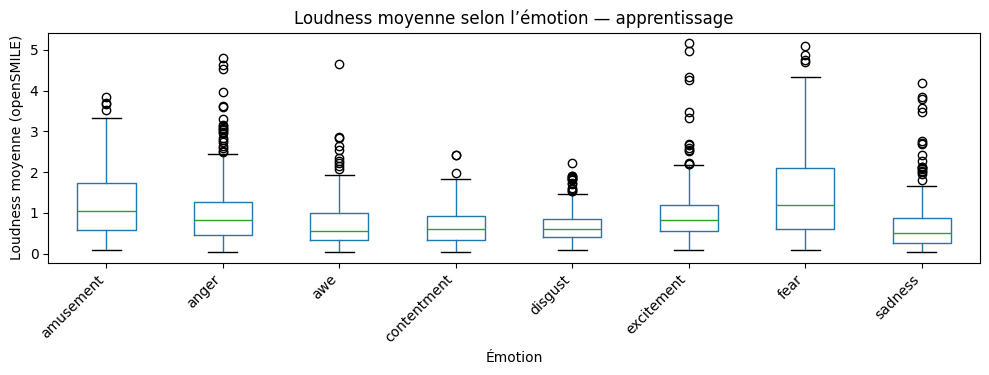

In [ ]:
# Comparer la loudness moyenne entre les émotions
table_analyse_audio.boxplot(
    column="loudness_sma3_amean",
    by="emotion",
    figsize=(10, 4),
    grid=False
)

plt.suptitle("")
plt.title("Loudness moyenne selon l’émotion — apprentissage")
plt.xlabel("Émotion")
plt.ylabel("Loudness moyenne (openSMILE)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


La loudness médiane est plus élevée pour "fear" et "amusement",
et plus faible pour "sadness". Les valeurs sont également
plus dispersées pour "fear".

Les distributions se recouvrent largement.


### 6.2. Hauteur du son selon l’émotion

Nous étudions la F0 moyenne estimée, exprimée en demi-tons
par rapport à une référence de 27,5 Hz.

Nous examinons d’abord les valeurs égales à zéro avant de comparer
les hauteurs estimées entre les émotions.


In [ ]:
# Identifier la caractéristique décrivant la F0 moyenne
colonne_pitch = "F0semitoneFrom27.5Hz_sma3nz_amean"

# Repérer les extraits dont la valeur est égale à zéro
pitch_nul = table_analyse_audio[colonne_pitch] == 0

print("Extraits concernés :", pitch_nul.sum())

# Examiner les mesures de F0 et de segments voisés
display(table_analyse_audio.loc[pitch_nul, [
    "emotion",
    colonne_pitch,
    "VoicedSegmentsPerSec"
]].head(10))


Extraits concernés : 10


,emotion,F0semitoneFrom27.5Hz_sma3nz_amean,VoicedSegmentsPerSec
video_id,,,
00017_clip_006,contentment,0.0,0.0
00130_clip_006,sadness,0.0,0.0
00130_clip_007,sadness,0.0,0.0
00132_clip_022,anger,0.0,0.0
00138_clip_010,contentment,0.0,0.0
00138_clip_018,sadness,0.0,0.0
00175_clip_038,fear,0.0,0.0
00200_clip_020,anger,0.0,0.0
00204_clip_016,contentment,0.0,0.0


Les 10 extraits concernés ne présentent aucun segment voisé détecté.
Leur F0 égale à zéro indique ici une absence de hauteur détectée,
sans signifier une absence de son.

Nous les écartons uniquement de ce graphique. Tous les extraits
restent conservés pour la modélisation.


Extraits représentés : 2197


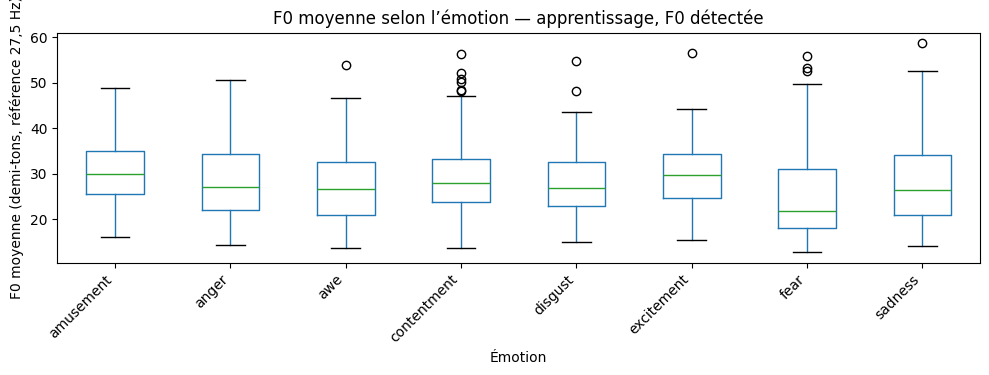

In [ ]:
# Sélectionner les extraits avec une F0 détectée pour ce graphique
table_pitch = table_analyse_audio.loc[~pitch_nul].copy()

print("Extraits représentés :", len(table_pitch))

# Comparer la F0 moyenne entre les émotions
table_pitch.boxplot(
    column=colonne_pitch,
    by="emotion",
    figsize=(10, 4),
    grid=False
)

plt.suptitle("")
plt.title("F0 moyenne selon l’émotion — apprentissage, F0 détectée")
plt.xlabel("Émotion")
plt.ylabel("F0 moyenne (demi-tons, référence 27,5 Hz)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Parmi les extraits avec une F0 détectée, la médiane est plus faible
pour "fear" et plus élevée pour "amusement" et "excitement".

Les distributions se recouvrent largement.


### 6.3. Variations du spectre sonore selon l’émotion

Le flux spectral mesure les changements du spectre entre des trames
successives. Une valeur moyenne plus élevée indique davantage
de variations spectrales pendant l’extrait.


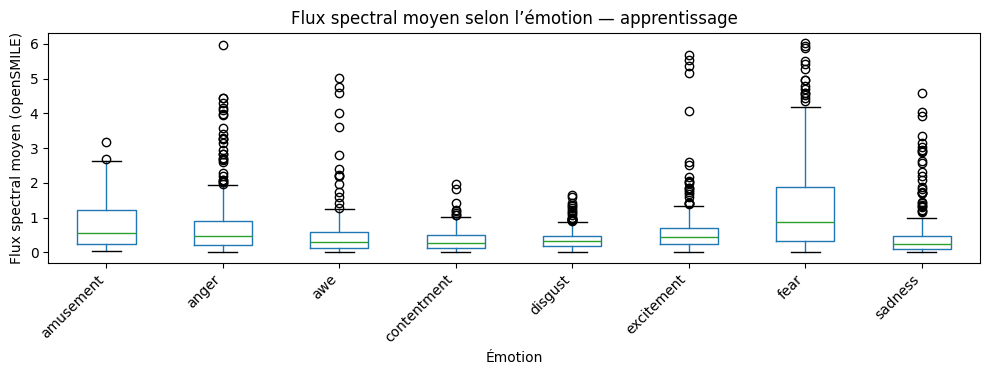

In [ ]:
# Comparer le flux spectral moyen entre les émotions
table_analyse_audio.boxplot(
    column="spectralFlux_sma3_amean",
    by="emotion",
    figsize=(10, 4),
    grid=False
)

plt.suptitle("")
plt.title("Flux spectral moyen selon l’émotion — apprentissage")
plt.xlabel("Émotion")
plt.ylabel("Flux spectral moyen (openSMILE)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Le flux spectral médian est plus élevé pour "fear", dont les valeurs
sont également plus dispersées. Les médianes sont plus faibles
pour "contentment" et "sadness".

Les distributions se recouvrent largement.


### 6.4. Organisation temporelle des segments voisés

Nous comparons le nombre de segments voisés détectés par seconde.
Ces segments correspondent aux passages où l’algorithme détecte une F0.

Cette mesure décrit une partie de l’organisation temporelle du son.
Elle ne représente pas directement le débit de parole.


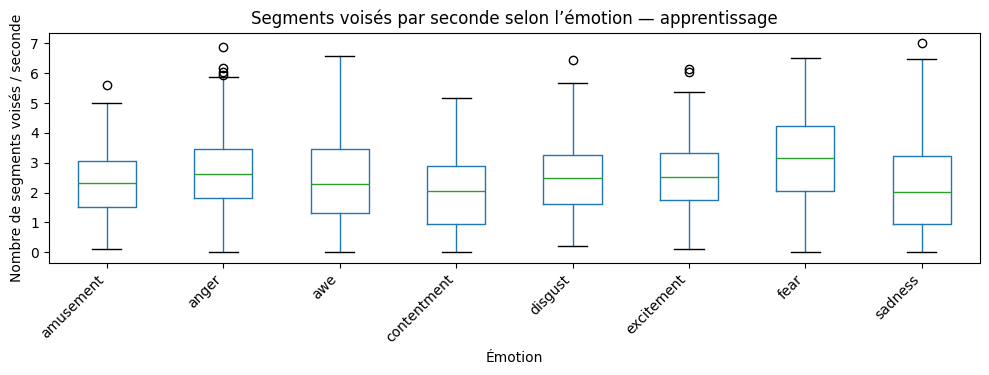

In [ ]:
# Comparer le nombre de segments voisés détectés par seconde
table_analyse_audio.boxplot(
    column="VoicedSegmentsPerSec",
    by="emotion",
    figsize=(10, 4),
    grid=False
)

plt.suptitle("")
plt.title("Segments voisés par seconde selon l’émotion — apprentissage")
plt.xlabel("Émotion")
plt.ylabel("Nombre de segments voisés / seconde")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Le nombre médian de segments voisés par seconde est plus élevé
pour "fear" et plus faible pour "contentment" et "sadness".

Les distributions se recouvrent largement entre les émotions.


### 6.5. Extraits de faible niveau sonore

Nous utilisons le 5e percentile de la loudness moyenne pour repérer
les extraits relativement peu sonores dans l’ensemble d’apprentissage.

Nous comparons leur proportion dans chaque émotion.


In [ ]:
# Définir le seuil à partir de l’apprentissage
seuil_faible_niveau = table_analyse_audio["loudness_sma3_amean"].quantile(0.05)

# Identifier les extraits de faible niveau sonore
analyse_niveau = table_analyse_audio[[
    "emotion", "loudness_sma3_amean"
]].copy()

analyse_niveau["faible_niveau"] = (
    analyse_niveau["loudness_sma3_amean"] <= seuil_faible_niveau
)

# Compter les extraits concernés par émotion
bilan_niveau = analyse_niveau.groupby("emotion")["faible_niveau"].agg(
    ["sum", "count"]
)

bilan_niveau.columns = ["Extraits de faible niveau", "Total des extraits"]

bilan_niveau["Proportion (%)"] = (
    100 * bilan_niveau["Extraits de faible niveau"]
    / bilan_niveau["Total des extraits"]
)

print("Seuil de loudness :", round(seuil_faible_niveau, 4))
print("Extraits concernés :", analyse_niveau["faible_niveau"].sum())

display(bilan_niveau.round(2))


Seuil de loudness : 0.1846
Extraits concernés : 111


,Extraits de faible niveau,Total des extraits,Proportion (%)
emotion,,,
amusement,1,174,0.57
anger,13,483,2.69
awe,13,206,6.31
contentment,23,265,8.68
disgust,6,211,2.84
excitement,4,252,1.59
fear,13,371,3.50
sadness,38,245,15.51


Avec ce seuil, 111 extraits présentent un faible niveau sonore.
Ils sont proportionnellement plus fréquents pour "sadness"
et "contentment", et moins fréquents pour "amusement" et "excitement".

Nous observons une association entre le faible niveau sonore et certaines
émotions.


## 7. Préparation des données pour la modélisation

Nous séparons les caractéristiques acoustiques et les émotions à prédire.
Les entrées et les étiquettes sont alignées grâce aux identifiants des extraits.


In [ ]:
# Entrées du modèle : les 88 caractéristiques acoustiques
X_train = caracteristiques_apprentissage.copy()

# Émotions à prédire, dans le même ordre que les caractéristiques
y_train = (
    audio_apprentissage
    .set_index("video_id")["emotion"]
    .reindex(X_train.index)
)

# Vérifier les dimensions et les étiquettes
print("Dimensions de X_train :", X_train.shape)
print("Dimensions de y_train :", y_train.shape)
print("Nombre d’émotions :", y_train.nunique())
print("Étiquettes manquantes :", y_train.isna().sum())


Dimensions de X_train : (2207, 88)
Dimensions de y_train : (2207,)
Nombre d’émotions : 8
Étiquettes manquantes : 0


## 8. Définition du modèle de référence

Nous utilisons une régression logistique précédée d’une standardisation
des caractéristiques.

La pondération des classes tient compte des effectifs inégaux des émotions.
La standardisation sera apprise uniquement sur l’ensemble d’apprentissage.


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Regrouper la standardisation et le classifieur
modele_audio = Pipeline([
    ("standardisation", StandardScaler()),
    ("classification", LogisticRegression(
        class_weight="balanced",
        max_iter=2000
    ))
])

print(modele_audio)


Pipeline(steps=[('standardisation', StandardScaler()),
                ('classification',
                 LogisticRegression(class_weight='balanced', max_iter=2000))])


### 8.1. Entraînement du modèle


In [ ]:
# Apprendre la standardisation et entraîner le classifieur
modele_audio.fit(X_train, y_train)

print("Entraînement terminé.")

# Ordre des émotions utilisé dans les diapositives
ordre_emotions = [
    "amusement",
    "awe",
    "contentment",
    "excitement",
    "anger",
    "disgust",
    "fear",
    "sadness"
]

print("Ordre de présentation :", ordre_emotions)


Entraînement terminé.
Ordre de présentation : ['amusement', 'awe', 'contentment', 'excitement', 'anger', 'disgust', 'fear', 'sadness']


## 9. Préparation de l’ensemble de développement

Nous préparons les mêmes caractéristiques acoustiques pour les extraits
de développement. Cet ensemble servira à comparer les réglages du modèle.


In [ ]:
# Sélectionner les extraits de développement
audio_developpement = donnees_audio[
    donnees_audio["split"] == "dev"
].copy()

# Définir le chemin des caractéristiques de développement
chemin_caracteristiques_dev = (
    dossier_projet
    / "caracteristiques_audio"
    / f"egemapsv02_dev_{frequence_exemple}Hz.csv"
)

print("Extraits de développement :", len(audio_developpement))
print(
    "Caractéristiques déjà sauvegardées :",
    chemin_caracteristiques_dev.is_file()
)


Extraits de développement : 442
Caractéristiques déjà sauvegardées : True


### 9.1. Extraction et sauvegarde des caractéristiques

Nous calculons les caractéristiques des extraits de développement
avec les mêmes paramètres que pour l’apprentissage.

Nous sauvegardons le résultat pour pouvoir le réutiliser.


In [ ]:
if not chemin_caracteristiques_dev.is_file():
    mesures_developpement = []

    with zipfile.ZipFile(chemin_zip, "r") as archive:
        for numero, extrait in enumerate(
            audio_developpement.itertuples(index=False),
            start=1
        ):
            # Lire le signal en mono à sa fréquence d’origine
            contenu = io.BytesIO(archive.read(extrait.chemin_audio_zip))
            signal, frequence = librosa.load(contenu, sr=None, mono=True)

            if frequence != frequence_exemple:
                raise ValueError(
                    f"Fréquence inattendue pour {extrait.video_id} : {frequence} Hz"
                )

            # Extraire les caractéristiques et conserver l’identifiant
            valeurs = extracteur_audio.process_signal(
                signal, frequence
            ).iloc[0].to_dict()

            valeurs["video_id"] = extrait.video_id
            mesures_developpement.append(valeurs)

            if numero % 100 == 0:
                print("Extraits traités :", numero)

    caracteristiques_developpement = pd.DataFrame(
        mesures_developpement
    ).set_index("video_id")

    # Sauvegarder les caractéristiques sur Drive
    chemin_caracteristiques_dev.parent.mkdir(parents=True, exist_ok=True)

    caracteristiques_developpement.to_csv(
        chemin_caracteristiques_dev,
        index_label="video_id"
    )

    print("Dimensions :", caracteristiques_developpement.shape)
    print("Fichier sauvegardé :", chemin_caracteristiques_dev)


### 9.2. Chargement des caractéristiques sauvegardées

Cette cellule reprend les poids retenus et le prétraitement associé.


In [ ]:
caracteristiques_developpement = pd.read_csv(
    chemin_caracteristiques_dev, index_col="video_id"
)
caracteristiques_developpement = verifier_caracteristiques(
    caracteristiques_developpement, audio_developpement, X_train.columns
)
print("Dimensions :", caracteristiques_developpement.shape)


Dimensions : (442, 88)


### 9.3. Préparation des données de développement

Nous préparons les caractéristiques et les émotions des extraits
de développement.


In [ ]:
# Placer les caractéristiques dans le même ordre que pour train
X_dev = caracteristiques_developpement.loc[:, X_train.columns].copy()

# Aligner les émotions sur les identifiants des caractéristiques
y_dev = (
    audio_developpement
    .set_index("video_id")["emotion"]
    .reindex(X_dev.index)
)

# Vérifier les dimensions, les valeurs et les étiquettes
print("Dimensions de X_dev :", X_dev.shape)
print("Dimensions de y_dev :", y_dev.shape)
print("Valeurs numériques toutes finies :", np.isfinite(X_dev.to_numpy()).all())
print("Étiquettes manquantes :", y_dev.isna().sum())


Dimensions de X_dev : (442, 88)
Dimensions de y_dev : (442,)
Valeurs numériques toutes finies : True
Étiquettes manquantes : 0


## 10. Évaluation sur l’ensemble de développement

Nous évaluons le modèle sur les extraits de développement.

Nous calculons l’accuracy, qui représente la proportion de prédictions
correctes, et le F1-score macro, qui donne le même poids à chaque émotion.


In [ ]:
from sklearn.metrics import accuracy_score, f1_score

# Prédire les émotions des extraits de développement
predictions_dev = modele_audio.predict(X_dev)

# Comparer les prédictions aux émotions attendues
accuracy_dev = accuracy_score(y_dev, predictions_dev)

f1_macro_dev = f1_score(
    y_dev,
    predictions_dev,
    labels=ordre_emotions,
    average="macro",
    zero_division=0
)

print("Accuracy dev :", round(accuracy_dev, 4))
print("F1-score macro dev :", round(f1_macro_dev, 4))


Accuracy dev : 0.1991
F1-score macro dev : 0.1988


### 10.1. Comparaison avec une référence simple

Nous comparons notre modèle à une référence qui prédit toujours
l’émotion la plus fréquente dans l’apprentissage.


In [ ]:
from sklearn.dummy import DummyClassifier

# Apprendre uniquement quelle émotion est la plus fréquente
modele_majoritaire = DummyClassifier(strategy="most_frequent")
modele_majoritaire.fit(X_train, y_train)

predictions_majoritaires = modele_majoritaire.predict(X_dev)

accuracy_majoritaire = accuracy_score(y_dev, predictions_majoritaires)
f1_majoritaire = f1_score(
    y_dev,
    predictions_majoritaires,
    labels=ordre_emotions,
    average="macro",
    zero_division=0
)

print("Accuracy de référence :", round(accuracy_majoritaire, 4))
print("F1 macro de référence :", round(f1_majoritaire, 4))


Accuracy de référence : 0.2217
F1 macro de référence : 0.0454


In [ ]:
chemin_logistique = dossier_modeles / "egemaps_logistique.joblib"


In [ ]:
if reentrainer or not chemin_logistique.is_file():
    resultats_logistiques = []
    modeles_logistiques = {}

    for valeur_C in [0.1, 1.0, 10.0]:
        modele_candidat = Pipeline([
            ("standardisation", StandardScaler()),
            ("classification", LogisticRegression(
                C=valeur_C,
                class_weight="balanced",
                max_iter=2000
            ))
        ])

        # Entraîner sur train et évaluer sur dev
        modele_candidat.fit(X_train, y_train)
        predictions = modele_candidat.predict(X_dev)

        score = f1_score(
            y_dev,
            predictions,
            labels=ordre_emotions,
            average="macro",
            zero_division=0
        )

        resultats_logistiques.append({
            "C": valeur_C,
            "F1 macro dev": score
        })
        modeles_logistiques[valeur_C] = modele_candidat

    # Classer les trois réglages
    classement_logistique = (
        pd.DataFrame(resultats_logistiques)
        .sort_values("F1 macro dev", ascending=False)
        .reset_index(drop=True)
    )

    display(classement_logistique.round(4))

    # Conserver le meilleur modèle parmi les trois candidats
    meilleur_C = float(classement_logistique.iloc[0]["C"])
    modele_logistique = modeles_logistiques[meilleur_C]

    print("C retenu :", meilleur_C)
    joblib.dump(modele_logistique, chemin_logistique)


### 10.2. Chargement de la régression logistique

Cette cellule reprend les poids retenus et le prétraitement associé.


In [ ]:
modele_logistique = joblib.load(chemin_logistique)
assert list(modele_logistique.feature_names_in_) == X_train.columns.tolist()
print("C retenu :", modele_logistique.named_steps["classification"].C)


C retenu : 0.1


## 11. Modélisation par réseau de neurones

Nous utilisons un réseau de neurones de type MLP avec les mêmes
88 caractéristiques acoustiques.


In [ ]:
# Apprendre la standardisation uniquement sur train
standardisation_nn = StandardScaler()

X_train_nn = standardisation_nn.fit_transform(X_train).astype("float32")
X_dev_nn = standardisation_nn.transform(X_dev).astype("float32")

# Associer chaque émotion à un code de 0 à 7
emotion_vers_indice = {
    emotion: indice
    for indice, emotion in enumerate(ordre_emotions)
}

y_train_nn = y_train.map(emotion_vers_indice).to_numpy(dtype="int32")
y_dev_nn = y_dev.map(emotion_vers_indice).to_numpy(dtype="int32")

print("Dimensions train :", X_train_nn.shape)
print("Dimensions dev :", X_dev_nn.shape)
print("Codage des émotions :", emotion_vers_indice)


Dimensions train : (2207, 88)
Dimensions dev : (442, 88)
Codage des émotions : {'amusement': 0, 'awe': 1, 'contentment': 2, 'excitement': 3, 'anger': 4, 'disgust': 5, 'fear': 6, 'sadness': 7}


### 11.1. Définition du réseau

Nous utilisons trois couches cachées de 256, 128 et 64 neurones,
avec des activations ReLU et du dropout.

La sortie fournit huit probabilités correspondant aux émotions.


In [ ]:
import tensorflow as tf

tf.config.set_visible_devices([], "GPU")

# Préparer une nouvelle expérience
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

# Créer un nouveau réseau
modele_nn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_nn.shape[1],)),

    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(len(ordre_emotions), activation="softmax")
])

# Créer également un nouvel optimiseur
modele_nn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

modele_nn.summary()

print(
    "Taux d’apprentissage initial :",
    round(float(modele_nn.optimizer.learning_rate.numpy()), 6)
)
print(
    "Mises à jour déjà effectuées :",
    int(modele_nn.optimizer.iterations.numpy())
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        22,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 64,456 (251.78 KB)

 Trainable params: 64,456 (251.78 KB)

 Non-trainable params: 0 (0.00 B)

Taux d’apprentissage initial : 0.001
Mises à jour déjà effectuées : 0


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

# Calculer les poids à partir des étiquettes d’apprentissage
classes_train = np.unique(y_train_nn)

poids_calcules = compute_class_weight(
    class_weight="balanced",
    classes=classes_train,
    y=y_train_nn
)

poids_classes = {
    int(classe): float(poids)
    for classe, poids in zip(classes_train, poids_calcules)
}


### 11.2. Entraînement du réseau

Nous entraînons le réseau pendant un maximum de 100 époques,
avec une pondération des classes.


In [ ]:
if reentrainer or not keras_disponible("egemaps_nn"):
    # Vérifier que le réseau vient d’être recréé
    assert int(modele_nn.optimizer.iterations.numpy()) == 0, (
        "Relancer la cellule de définition du réseau."
    )

    # Calculer le F1 macro dev après chaque époque
    class SuiviF1Macro(tf.keras.callbacks.Callback):
        def on_epoch_end(self, epoch, logs=None):
            probabilites = self.model(X_dev_nn, training=False).numpy()
            predictions = np.argmax(probabilites, axis=1)

            if logs is not None:
                logs["val_f1_macro"] = f1_score(
                    y_dev_nn,
                    predictions,
                    labels=np.arange(len(ordre_emotions)),
                    average="macro",
                    zero_division=0
                )

    # Conserver la même réduction du taux d’apprentissage
    reduction_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=4,
        min_lr=0.00001,
        verbose=1
    )

    # Choisir les poids donnant le meilleur F1 macro dev
    arret_precoce = tf.keras.callbacks.EarlyStopping(
        monitor="val_f1_macro",
        mode="max",
        patience=12,
        restore_best_weights=True,
        verbose=1
    )

    historique_nn = modele_nn.fit(
        X_train_nn,
        y_train_nn,
        validation_data=(X_dev_nn, y_dev_nn),
        epochs=100,
        batch_size=32,
        class_weight=poids_classes,
        callbacks=[SuiviF1Macro(), reduction_lr, arret_precoce],
        verbose=2
    )

    print("Époques effectuées :", len(historique_nn.history["loss"]))
    print(
        "Meilleur F1 macro dev :",
        round(max(historique_nn.history["val_f1_macro"]), 4)
    )
    sauvegarder_keras(modele_nn, standardisation_nn, "egemaps_nn", X_train.columns)


### 11.3. Chargement du réseau eGeMAPS

Cette cellule reprend les poids retenus et le prétraitement associé.


In [ ]:
dossier_chargement = dossier_modeles / "egemaps_nn"
verifier_ordre_sauvegarde(dossier_chargement)
modele_nn = tf.keras.models.load_model(
    dossier_chargement / "classifieur.keras", compile=False
)
standardisation_nn = joblib.load(dossier_chargement / "standardisation.joblib")
assert list(standardisation_nn.feature_names_in_) == X_train.columns.tolist()
X_train_nn = standardisation_nn.transform(X_train).astype("float32")
X_dev_nn = standardisation_nn.transform(X_dev).astype("float32")
print("Modèle chargé :", dossier_chargement)


Modèle chargé : /content/drive/MyDrive/SID/modeles_audio/egemaps_nn


In [ ]:
from sklearn.metrics import classification_report

# Prédire avec les poids restaurés par l’arrêt précoce
probabilites_dev_nn = modele_nn.predict(X_dev_nn, verbose=0)

# Convertir les probabilités en noms d’émotions
indices_dev_nn = np.argmax(probabilites_dev_nn, axis=1)
predictions_dev_nn = np.array(ordre_emotions)[indices_dev_nn]

# Calculer les scores sur dev
f1_macro_nn = f1_score(
    y_dev,
    predictions_dev_nn,
    labels=ordre_emotions,
    average="macro",
    zero_division=0
)

print("Accuracy NN :", round(accuracy_score(y_dev, predictions_dev_nn), 4))
print("F1 macro NN :", round(f1_macro_nn, 4))

print(classification_report(
    y_dev,
    predictions_dev_nn,
    labels=ordre_emotions,
    digits=3,
    zero_division=0
))


Accuracy NN : 0.2127
F1 macro NN : 0.2017
              precision    recall  f1-score   support

   amusement      0.192     0.286     0.230        35
         awe      0.079     0.075     0.077        40
 contentment      0.227     0.315     0.264        54
  excitement      0.269     0.275     0.272        51
       anger      0.412     0.071     0.122        98
     disgust      0.088     0.116     0.100        43
        fear      0.312     0.324     0.318        74
     sadness      0.189     0.298     0.231        47

    accuracy                          0.213       442
   macro avg      0.221     0.220     0.202       442
weighted avg      0.253     0.213     0.203       442



## 12. Caractéristiques pré-entraînées avec YAMNet

Les résultats avec eGeMAPS restent faibles. Nous essayons YAMNet comme
extracteur pré-entraîné, en gardant ses paramètres fixes. Nous comparons
ses embeddings seuls, puis associés aux 88 caractéristiques eGeMAPS.


### 12.1. Chargement de YAMNet


In [ ]:
import tensorflow_hub as hub

# Charger le modèle pré-entraîné
modele_yamnet = hub.load("https://tfhub.dev/google/yamnet/1")

# Fréquence requise pour cette nouvelle extraction
frequence_yamnet = 16000

print("Version de TensorFlow Hub :", hub.__version__)
print("YAMNet chargé.")
print("Fréquence attendue :", frequence_yamnet, "Hz")


/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


Version de TensorFlow Hub : 0.16.1
YAMNet chargé.
Fréquence attendue : 16000 Hz


### 12.2. Extraction sur un exemple

Nous rééchantillonnons l’exemple audio à 16 kHz pour respecter
le format attendu par YAMNet.


In [ ]:
# Préparer l’exemple à la fréquence attendue par YAMNet
signal_exemple_yamnet = librosa.resample(
    signal_exemple,
    orig_sr=frequence_exemple,
    target_sr=frequence_yamnet
).astype("float32")

# Extraire les embeddings des fenêtres temporelles
_, embeddings_exemple_yamnet, _ = modele_yamnet(signal_exemple_yamnet)

# Résumer l’extrait par la moyenne des embeddings
vecteur_exemple_yamnet = tf.reduce_mean(
    embeddings_exemple_yamnet,
    axis=0
).numpy()

print("Embeddings par fenêtre :", embeddings_exemple_yamnet.shape)
print("Vecteur de l’extrait :", vecteur_exemple_yamnet.shape)
print("Valeurs toutes finies :", np.isfinite(vecteur_exemple_yamnet).all())


Embeddings par fenêtre : (9, 1024)
Vecteur de l’extrait : (1024,)
Valeurs toutes finies : True


### 12.3. Extraction des caractéristiques


In [ ]:
def extraire_caracteristiques_yamnet(extraits):
    vecteurs = []

    with zipfile.ZipFile(chemin_zip, "r") as archive:
        for numero, extrait in enumerate(
            extraits.itertuples(index=False),
            start=1
        ):
            # Lire le signal au format attendu par YAMNet
            contenu = io.BytesIO(archive.read(extrait.chemin_audio_zip))
            signal, _ = librosa.load(
                contenu,
                sr=frequence_yamnet,
                mono=True
            )

            # Calculer un vecteur moyen pour l’extrait
            _, embeddings, _ = modele_yamnet(signal.astype("float32"))
            vecteur = tf.reduce_mean(embeddings, axis=0).numpy()
            vecteurs.append(vecteur)

            if numero % 100 == 0:
                print("Extraits traités :", numero)

    # Construire la table avec les identifiants des extraits
    colonnes = [f"yamnet_{i}" for i in range(1024)]
    table = pd.DataFrame(vecteurs, columns=colonnes)
    table["video_id"] = extraits["video_id"].to_numpy()

    return table.set_index("video_id")


#### Chargement ou extraction des caractéristiques

Nous lisons les CSV existants. L’extraction ne se lance que si un fichier manque.


In [ ]:
# Définir le fichier de sauvegarde
chemin_yamnet_train = (
    dossier_projet
    / "caracteristiques_audio"
    / "yamnet_v1_mean_train_16000Hz.csv"
)

if chemin_yamnet_train.is_file():
    # Réutiliser les caractéristiques déjà calculées
    caracteristiques_yamnet_train = pd.read_csv(
        chemin_yamnet_train,
        index_col="video_id"
    )
    print("Caractéristiques chargées.")

else:
    # Calculer les caractéristiques une seule fois
    caracteristiques_yamnet_train = extraire_caracteristiques_yamnet(
        audio_apprentissage
    )

    assert np.isfinite(caracteristiques_yamnet_train.to_numpy()).all()

    chemin_yamnet_train.parent.mkdir(parents=True, exist_ok=True)
    caracteristiques_yamnet_train.to_csv(
        chemin_yamnet_train,
        index_label="video_id"
    )
    print("Caractéristiques sauvegardées.")

# Vérifier la taille et les identifiants
assert caracteristiques_yamnet_train.shape == (len(audio_apprentissage), 1024)
assert set(caracteristiques_yamnet_train.index) == set(
    audio_apprentissage["video_id"]
)

print("Dimensions train :", caracteristiques_yamnet_train.shape)


Caractéristiques chargées.
Dimensions train : (2207, 1024)


In [ ]:
caracteristiques_yamnet_train = verifier_caracteristiques(
    caracteristiques_yamnet_train, audio_apprentissage, [f"yamnet_{i}" for i in range(1024)]
)


In [ ]:
# Définir le fichier de sauvegarde pour dev
chemin_yamnet_dev = (
    dossier_projet
    / "caracteristiques_audio"
    / "yamnet_v1_mean_dev_16000Hz.csv"
)

if chemin_yamnet_dev.is_file():
    caracteristiques_yamnet_dev = pd.read_csv(
        chemin_yamnet_dev,
        index_col="video_id"
    )
    print("Caractéristiques chargées.")

else:
    caracteristiques_yamnet_dev = extraire_caracteristiques_yamnet(
        audio_developpement
    )

    assert np.isfinite(caracteristiques_yamnet_dev.to_numpy()).all()

    chemin_yamnet_dev.parent.mkdir(parents=True, exist_ok=True)
    caracteristiques_yamnet_dev.to_csv(
        chemin_yamnet_dev,
        index_label="video_id"
    )
    print("Caractéristiques sauvegardées.")

# Vérifier la taille et les identifiants
assert caracteristiques_yamnet_dev.shape == (len(audio_developpement), 1024)
assert set(caracteristiques_yamnet_dev.index) == set(
    audio_developpement["video_id"]
)

print("Dimensions dev :", caracteristiques_yamnet_dev.shape)


Caractéristiques chargées.
Dimensions dev : (442, 1024)


In [ ]:
caracteristiques_yamnet_dev = verifier_caracteristiques(
    caracteristiques_yamnet_dev, audio_developpement, [f"yamnet_{i}" for i in range(1024)]
)


### 12.4. Construction des deux représentations

Nous préparons une représentation utilisant uniquement YAMNet,
puis une seconde associant YAMNet et eGeMAPS.


In [ ]:
# Conserver le même ordre de colonnes YAMNet
colonnes_yamnet = [f"yamnet_{i}" for i in range(1024)]

# Aligner les lignes sur les données déjà utilisées pour la modélisation
X_train_yamnet = caracteristiques_yamnet_train.loc[
    X_train.index, colonnes_yamnet
].copy()

X_dev_yamnet = caracteristiques_yamnet_dev.loc[
    X_dev.index, colonnes_yamnet
].copy()

# Associer les caractéristiques des deux méthodes
X_train_combine = pd.concat([X_train_yamnet, X_train], axis=1)
X_dev_combine = pd.concat([X_dev_yamnet, X_dev], axis=1)

# Vérifier les valeurs obtenues
for table in [X_train_yamnet, X_dev_yamnet, X_train_combine, X_dev_combine]:
    assert np.isfinite(table.to_numpy()).all(), "Valeurs invalides détectées."

print("YAMNet — train :", X_train_yamnet.shape)
print("YAMNet — dev :", X_dev_yamnet.shape)
print("YAMNet + eGeMAPS — train :", X_train_combine.shape)
print("YAMNet + eGeMAPS — dev :", X_dev_combine.shape)


YAMNet — train : (2207, 1024)
YAMNet — dev : (442, 1024)
YAMNet + eGeMAPS — train : (2207, 1112)
YAMNet + eGeMAPS — dev : (442, 1112)


### 12.5. Standardisation des caractéristiques

Pour chaque représentation, nous calculons la standardisation sur train, puis nous l’appliquons à dev.


In [ ]:
# Standardiser les caractéristiques YAMNet
standardisation_yamnet = StandardScaler()

X_train_yamnet_nn = standardisation_yamnet.fit_transform(
    X_train_yamnet
).astype("float32")

X_dev_yamnet_nn = standardisation_yamnet.transform(
    X_dev_yamnet
).astype("float32")

# Standardiser les caractéristiques combinées
standardisation_combinee = StandardScaler()

X_train_combine_nn = standardisation_combinee.fit_transform(
    X_train_combine
).astype("float32")

X_dev_combine_nn = standardisation_combinee.transform(
    X_dev_combine
).astype("float32")

print("Entrées YAMNet :", X_train_yamnet_nn.shape, X_dev_yamnet_nn.shape)
print("Entrées combinées :", X_train_combine_nn.shape, X_dev_combine_nn.shape)


Entrées YAMNet : (2207, 1024) (442, 1024)
Entrées combinées : (2207, 1112) (442, 1112)


### 12.6. Définition des classifieurs

Nous utilisons la même architecture pour YAMNet seul et YAMNet associé
à eGeMAPS


In [ ]:
def creer_classifieur_audio(nombre_entrees):
    # Fixer la graine pour faciliter la reproduction
    tf.keras.utils.set_random_seed(42)

    modele = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(nombre_entrees,)),

        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dropout(0.3),

        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(0.3),

        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.2),

        tf.keras.layers.Dense(len(ordre_emotions), activation="softmax")
    ])

    modele.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return modele


# Créer deux classifieurs indépendants
modele_yamnet_nn = creer_classifieur_audio(X_train_yamnet_nn.shape[1])
modele_combine_nn = creer_classifieur_audio(X_train_combine_nn.shape[1])

print("Entrée YAMNet :", modele_yamnet_nn.input_shape)
print("Entrée combinée :", modele_combine_nn.input_shape)
print("Sortie :", modele_yamnet_nn.output_shape)


Entrée YAMNet : (None, 1024)
Entrée combinée : (None, 1112)
Sortie : (None, 8)


### 12.7. Suivi du F1-score macro

Nous calculons le F1-score macro sur le développement après chaque époque.


In [ ]:
class SuiviF1MacroDev(tf.keras.callbacks.Callback):
    def __init__(self, entrees_dev, etiquettes_dev):
        super().__init__()
        self.entrees_dev = entrees_dev
        self.etiquettes_dev = etiquettes_dev

    def on_epoch_end(self, epoch, logs=None):
        # Prédire les émotions sur le développement
        probabilites = self.model(
            self.entrees_dev,
            training=False
        ).numpy()

        predictions = np.argmax(probabilites, axis=1)

        # Ajouter le score aux résultats de l’époque
        if logs is not None:
            logs["val_f1_macro"] = f1_score(
                self.etiquettes_dev,
                predictions,
                labels=np.arange(len(ordre_emotions)),
                average="macro",
                zero_division=0
            )


### 12.8. Entraînement avec YAMNet seul

Nous entraînons le classifieur sur les embeddings YAMNet.
Nous conservons la pondération des classes, la réduction du taux
d’apprentissage et l’arrêt précoce.


In [ ]:
if reentrainer or not keras_disponible("yamnet"):
    # Créer un classifieur neuf
    modele_yamnet_nn = creer_classifieur_audio(X_train_yamnet_nn.shape[1])

    # Suivre le F1 macro sur les entrées YAMNet de dev
    suivi_yamnet = SuiviF1MacroDev(X_dev_yamnet_nn, y_dev_nn)

    reduction_lr_yamnet = tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=4,
        min_lr=0.00001,
        verbose=1
    )

    arret_yamnet = tf.keras.callbacks.EarlyStopping(
        monitor="val_f1_macro",
        mode="max",
        patience=12,
        restore_best_weights=True,
        verbose=1
    )

    # Entraîner uniquement le classifieur
    historique_yamnet = modele_yamnet_nn.fit(
        X_train_yamnet_nn,
        y_train_nn,
        validation_data=(X_dev_yamnet_nn, y_dev_nn),
        epochs=100,
        batch_size=32,
        class_weight=poids_classes,
        callbacks=[suivi_yamnet, reduction_lr_yamnet, arret_yamnet],
        verbose=2
    )

    print("Époques effectuées :", len(historique_yamnet.history["loss"]))
    print(
        "Meilleur F1 macro dev :",
        round(max(historique_yamnet.history["val_f1_macro"]), 4)
    )
    sauvegarder_keras(modele_yamnet_nn, standardisation_yamnet, "yamnet", X_train_yamnet.columns)


#### Chargement du classifieur YAMNet

Cette cellule reprend les poids retenus et le prétraitement associé.


In [ ]:
dossier_chargement = dossier_modeles / "yamnet"
verifier_ordre_sauvegarde(dossier_chargement)
modele_yamnet_nn = tf.keras.models.load_model(
    dossier_chargement / "classifieur.keras", compile=False
)
standardisation_yamnet = joblib.load(dossier_chargement / "standardisation.joblib")
assert list(standardisation_yamnet.feature_names_in_) == X_train_yamnet.columns.tolist()
X_train_yamnet_nn = standardisation_yamnet.transform(X_train_yamnet).astype("float32")
X_dev_yamnet_nn = standardisation_yamnet.transform(X_dev_yamnet).astype("float32")
print("Modèle chargé :", dossier_chargement)


Modèle chargé : /content/drive/MyDrive/SID/modeles_audio/yamnet


### 12.9. Entraînement avec YAMNet et eGeMAPS

Nous entraînons le même classifieur sur les 1 112 caractéristiques combinées.


In [ ]:
if reentrainer or not keras_disponible("yamnet_egemaps_nn"):
    # Créer un nouveau classifieur pour les caractéristiques combinées
    modele_combine_nn = creer_classifieur_audio(X_train_combine_nn.shape[1])

    suivi_combine = SuiviF1MacroDev(X_dev_combine_nn, y_dev_nn)

    reduction_lr_combine = tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=4,
        min_lr=0.00001,
        verbose=1
    )

    arret_combine = tf.keras.callbacks.EarlyStopping(
        monitor="val_f1_macro",
        mode="max",
        patience=12,
        restore_best_weights=True,
        verbose=1
    )

    # Entraîner avec les mêmes réglages
    historique_combine = modele_combine_nn.fit(
        X_train_combine_nn,
        y_train_nn,
        validation_data=(X_dev_combine_nn, y_dev_nn),
        epochs=100,
        batch_size=32,
        class_weight=poids_classes,
        callbacks=[suivi_combine, reduction_lr_combine, arret_combine],
        verbose=2
    )

    print("Époques effectuées :", len(historique_combine.history["loss"]))
    print(
        "Meilleur F1 macro dev :",
        round(max(historique_combine.history["val_f1_macro"]), 4)
    )
    sauvegarder_keras(modele_combine_nn, standardisation_combinee, "yamnet_egemaps_nn", X_train_combine.columns)


#### Chargement du classifieur YAMNet + eGeMAPS

Cette cellule reprend les poids retenus et le prétraitement associé.


In [ ]:
dossier_chargement = dossier_modeles / "yamnet_egemaps_nn"
verifier_ordre_sauvegarde(dossier_chargement)
modele_combine_nn = tf.keras.models.load_model(
    dossier_chargement / "classifieur.keras", compile=False
)
standardisation_combinee = joblib.load(dossier_chargement / "standardisation.joblib")
assert list(standardisation_combinee.feature_names_in_) == X_train_combine.columns.tolist()
X_train_combine_nn = standardisation_combinee.transform(X_train_combine).astype("float32")
X_dev_combine_nn = standardisation_combinee.transform(X_dev_combine).astype("float32")
print("Modèle chargé :", dossier_chargement)


Modèle chargé : /content/drive/MyDrive/SID/modeles_audio/yamnet_egemaps_nn


### 12.10. Comparaison des représentations


In [ ]:
# Prédire avec les deux modèles restaurés
probabilites_dev_yamnet = modele_yamnet_nn.predict(
    X_dev_yamnet_nn, verbose=0
)

probabilites_dev_combine = modele_combine_nn.predict(
    X_dev_combine_nn, verbose=0
)

# Retrouver les noms des émotions dans l’ordre défini
noms_emotions = np.array(ordre_emotions)

predictions_dev_yamnet = noms_emotions[
    np.argmax(probabilites_dev_yamnet, axis=1)
]

predictions_dev_combine = noms_emotions[
    np.argmax(probabilites_dev_combine, axis=1)
]

# Comparer les scores
resultats_representations = []

for nom, predictions in [
    ("YAMNet", predictions_dev_yamnet),
    ("YAMNet + eGeMAPS", predictions_dev_combine)
]:
    resultats_representations.append({
        "Représentation": nom,
        "Accuracy dev": accuracy_score(y_dev, predictions),
        "F1 macro dev": f1_score(
            y_dev,
            predictions,
            labels=ordre_emotions,
            average="macro",
            zero_division=0
        )
    })

comparaison_representations = pd.DataFrame(resultats_representations)
display(comparaison_representations.round(4))


,Représentation,Accuracy dev,F1 macro dev
0,YAMNet,0.2149,0.2182
1,YAMNet + eGeMAPS,0.2376,0.2352


## 13. Analyse des erreurs sur le développement


In [ ]:
from sklearn.metrics import classification_report

# Examiner les performances pour chaque émotion
print(classification_report(
    y_dev,
    predictions_dev_yamnet,
    labels=ordre_emotions,
    digits=3,
    zero_division=0
))


              precision    recall  f1-score   support

   amusement      0.277     0.371     0.317        35
         awe      0.113     0.150     0.129        40
 contentment      0.155     0.167     0.161        54
  excitement      0.343     0.235     0.279        51
       anger      0.387     0.122     0.186        98
     disgust      0.087     0.163     0.114        43
        fear      0.271     0.257     0.264        74
     sadness      0.250     0.362     0.296        47

    accuracy                          0.215       442
   macro avg      0.235     0.228     0.218       442
weighted avg      0.257     0.215     0.217       442



### 13.1. Matrice de confusion


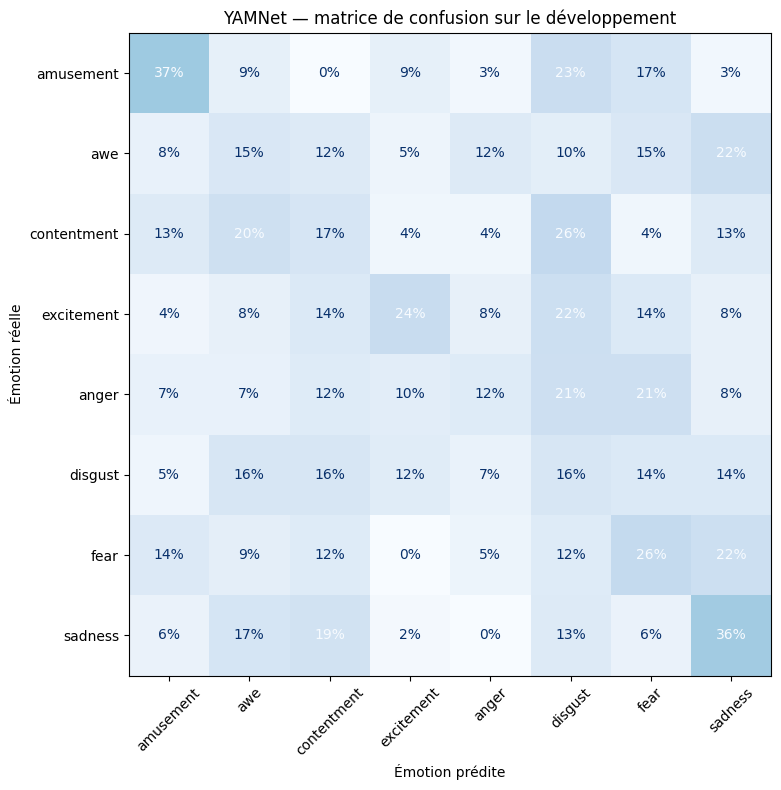

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_dev,
    predictions_dev_yamnet,
    labels=ordre_emotions,
    normalize="true",
    values_format=".0%",
    cmap="Blues",
    colorbar=False,
    xticks_rotation=45,
    im_kw={"vmin": 0, "vmax": 1},
    ax=ax
)

ax.set_title("YAMNet — matrice de confusion sur le développement")
ax.set_xlabel("Émotion prédite")
ax.set_ylabel("Émotion réelle")

plt.tight_layout()
plt.show()


La colère est davantage prédite comme de la peur ou du dégoût
que correctement reconnue. Le dégoût est souvent confondu avec
l’émerveillement et le contentement.


### 13.2. Vérification du modèle et des données

Nous vérifions l’alignement des caractéristiques et des étiquettes,
ainsi que la séparation des films entre apprentissage et développement.


In [ ]:
# Vérifier l’ordre des extraits et le codage des émotions
assert X_train_yamnet.index.equals(y_train.index)
assert X_dev_yamnet.index.equals(y_dev.index)

assert np.array_equal(
    y_train_nn, y_train.map(emotion_vers_indice).to_numpy()
)
assert np.array_equal(
    y_dev_nn, y_dev.map(emotion_vers_indice).to_numpy()
)

# Vérifier que les films sont différents entre les deux ensembles
assert set(audio_apprentissage["film_id"]).isdisjoint(
    set(audio_developpement["film_id"])
)

# Vérifier la cohérence de la standardisation
assert np.allclose(
    X_train_yamnet_nn,
    standardisation_yamnet.transform(X_train_yamnet)
)
assert np.allclose(
    X_dev_yamnet_nn,
    standardisation_yamnet.transform(X_dev_yamnet)
)

# Évaluer les mêmes poids sur train et dev, sans dropout
resultats_verification = []

for nom, entrees, etiquettes in [
    ("Train", X_train_yamnet_nn, y_train_nn),
    ("Dev", X_dev_yamnet_nn, y_dev_nn)
]:
    probabilites = modele_yamnet_nn.predict(entrees, verbose=0)
    assert probabilites.shape == (len(etiquettes), len(ordre_emotions))
    predictions = probabilites.argmax(axis=1)

    resultats_verification.append({
        "Ensemble": nom,
        "Accuracy": accuracy_score(etiquettes, predictions),
        "F1 macro": f1_score(
            etiquettes, predictions,
            labels=np.arange(len(ordre_emotions)),
            average="macro",
            zero_division=0
        )
    })

print("Vérifications réussies.")
display(pd.DataFrame(resultats_verification).round(4))


Vérifications réussies.


,Ensemble,Accuracy,F1 macro
0,Train,0.5134,0.5193
1,Dev,0.2149,0.2182


===============================================================

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

audio_apprentissage = donnees_audio[
    donnees_audio["split"] == "train"
].copy()

audio_developpement = donnees_audio[
    donnees_audio["split"] == "dev"
].copy()

ordre_emotions = [
    "amusement", "awe", "contentment", "excitement",
    "anger", "disgust", "fear", "sadness",
]

emotion_vers_indice = {
    emotion: indice for indice, emotion in enumerate(ordre_emotions)
}

## 14. Fine-tuning d’un modèle AST

Nous adaptons un modèle Audio Spectrogram Transformer préentraîné
sur AudioSet pour prédire les huit émotions du projet.


In [ ]:
import os

# Utiliser PyTorch pour cette expérience
os.environ["USE_TF"] = "0"

import torch
import transformers
from transformers import (
    ASTFeatureExtractor,
    ASTForAudioClassification,
    set_seed,
    Trainer, TrainingArguments, EarlyStoppingCallback, default_data_collator
)

set_seed(42)

assert torch.cuda.is_available(), "Activer un GPU pour cette section."
appareil_ast = torch.device("cuda")

memoire_libre, memoire_totale = torch.cuda.mem_get_info()

print("Version de PyTorch :", torch.__version__)
print("Version de Transformers :", transformers.__version__)
print("GPU :", torch.cuda.get_device_name(0))
print(
    f"Mémoire GPU disponible : "
    f"{memoire_libre / 1024**3:.1f} / "
    f"{memoire_totale / 1024**3:.1f} Gio"
)


Version de PyTorch : 2.11.0+cu130
Version de Transformers : 4.57.1
GPU : Tesla T4
Mémoire GPU disponible : 14.5 / 14.6 Gio


In [ ]:
sauvegarde_ast = (
    dossier_modeles / "ast" / "checkpoints" / "checkpoint-1518"
)

assert (sauvegarde_ast / "model.safetensors").is_file()

entrainer_ast = False

print("Checkpoint disponible :", sauvegarde_ast)
print("Entraînement AST désactivé.")

Checkpoint disponible : /content/drive/MyDrive/SID/modeles_audio/ast/checkpoints/checkpoint-1518
Entraînement AST désactivé.


### 14.2. Chargement et adaptation du modèle

Nous remplaçons le classifieur d’origine par une sortie à huit classes.
Nous entraînons ce nouveau classifieur et les deux derniers blocs
du Transformer. Les premières couches conservent leurs poids préentraînés.


In [ ]:
if entrainer_ast:
    set_seed(42)

    identifiant_ast = "MIT/ast-finetuned-audioset-10-10-0.4593"

    indice_vers_emotion = dict(enumerate(ordre_emotions))
    emotion_vers_indice = {
        emotion: indice for indice, emotion in indice_vers_emotion.items()
    }

    extracteur_ast = ASTFeatureExtractor.from_pretrained(identifiant_ast)

    modele_ast = ASTForAudioClassification.from_pretrained(
        identifiant_ast,
        num_labels=len(ordre_emotions),
        id2label=indice_vers_emotion,
        label2id=emotion_vers_indice,
        problem_type="single_label_classification",
        ignore_mismatched_sizes=True,
        hidden_dropout_prob=0.1,
        attention_probs_dropout_prob=0.1,
        attn_implementation="sdpa"
    )

    # Geler les paramètres de l’encodeur
    encodeur_ast = modele_ast.audio_spectrogram_transformer

    for parametre in encodeur_ast.parameters():
        parametre.requires_grad = False

    # Autoriser l’apprentissage des deux derniers blocs
    for bloc in encodeur_ast.encoder.layer[-2:]:
        for parametre in bloc.parameters():
            parametre.requires_grad = True

    # Adapter aussi la normalisation finale
    for parametre in encodeur_ast.layernorm.parameters():
        parametre.requires_grad = True

    modele_ast = modele_ast.to(appareil_ast)

    nombre_total = sum(p.numel() for p in modele_ast.parameters())
    nombre_entrainable = sum(
        p.numel() for p in modele_ast.parameters() if p.requires_grad
    )

    print("Nombre de classes :", modele_ast.config.num_labels)
    print(f"Paramètres totaux : {nombre_total:,}")
    print(f"Paramètres entraînables : {nombre_entrainable:,}")


In [ ]:
# Le prétraitement et les fenêtres sont aussi utilisés par les expériences suivantes.
extracteur_ast = ASTFeatureExtractor.from_pretrained(
    str(sauvegarde_ast) if sauvegarde_ast is not None and not entrainer_ast
    else "MIT/ast-finetuned-audioset-10-10-0.4593"
)
frequence_ast = extracteur_ast.sampling_rate
duree_fenetre_ast = 10
taille_fenetre_ast = duree_fenetre_ast * frequence_ast


### 14.4. Préparation des fichiers audio


In [ ]:
from pathlib import Path
import pandas as pd
import soundfile as sf

dossier_audio_ast = dossier_audio_temporaire
dossier_audio_ast.mkdir(parents=True, exist_ok=True)

extraits_ast = pd.concat(
    [audio_apprentissage, audio_developpement],
    ignore_index=True
).copy()

assert extraits_ast["video_id"].is_unique

chemins_ast = []
nombres_echantillons = []

with zipfile.ZipFile(chemin_zip, "r") as archive:
    for numero, extrait in enumerate(
        extraits_ast.itertuples(index=False), start=1
    ):
        chemin_local = dossier_audio_ast / f"{extrait.video_id}.wav"

        if not chemin_local.exists():
            contenu = io.BytesIO(archive.read(extrait.chemin_audio_zip))
            signal, _ = librosa.load(
                contenu, sr=frequence_ast, mono=True
            )
            sf.write(
                chemin_local, signal,
                frequence_ast, subtype="FLOAT"
            )

        chemins_ast.append(str(chemin_local))
        nombres_echantillons.append(sf.info(chemin_local).frames)

        if numero % 200 == 0:
            print("Extraits préparés :", numero)

extraits_ast["chemin_audio_ast"] = chemins_ast
extraits_ast["nb_echantillons_ast"] = nombres_echantillons
extraits_ast["label"] = extraits_ast["emotion"].map(emotion_vers_indice)

assert extraits_ast["label"].notna().all()
assert (extraits_ast["nb_echantillons_ast"] > 0).all()

audio_ast_train = extraits_ast[
    extraits_ast["split"] == "train"
].reset_index(drop=True)

audio_ast_dev = extraits_ast[
    extraits_ast["split"] == "dev"
].reset_index(drop=True)

print("Extraits train :", len(audio_ast_train))
print("Extraits dev :", len(audio_ast_dev))


Extraits préparés : 200
Extraits préparés : 400
Extraits préparés : 600
Extraits préparés : 800
Extraits préparés : 1000
Extraits préparés : 1200
Extraits préparés : 1400
Extraits préparés : 1600
Extraits préparés : 1800
Extraits préparés : 2000
Extraits préparés : 2200
Extraits préparés : 2400
Extraits préparés : 2600
Extraits train : 2207
Extraits dev : 442


### 14.5. Découpage des extraits de développement


In [ ]:
import numpy as np

fenetres_dev_ast = []

for extrait in audio_ast_dev.itertuples(index=False):
    nombre_fenetres = int(np.ceil(
        extrait.nb_echantillons_ast / taille_fenetre_ast
    ))

    dernier_debut = max(
        0, extrait.nb_echantillons_ast - taille_fenetre_ast
    )

    # Répartir les fenêtres du début jusqu’à la fin de l’extrait
    debuts = np.linspace(
        0, dernier_debut, num=nombre_fenetres, dtype=int
    )

    for debut in debuts:
        fenetres_dev_ast.append({
            "video_id": extrait.video_id,
            "chemin_audio_ast": extrait.chemin_audio_ast,
            "debut_ast": int(debut),
            "label": int(extrait.label)
        })

table_fenetres_dev_ast = pd.DataFrame(fenetres_dev_ast)

assert table_fenetres_dev_ast["video_id"].nunique() == len(audio_ast_dev)

print("Extraits de développement :", len(audio_ast_dev))
print("Fenêtres de développement :", len(table_fenetres_dev_ast))

display(
    table_fenetres_dev_ast[
        ["video_id", "debut_ast", "label"]
    ].head()
)


Extraits de développement : 442
Fenêtres de développement : 572


,video_id,debut_ast,label
0,00008_clip_001,0,0
1,00008_clip_002,0,6
2,00008_clip_002,115616,6
3,00008_clip_006,0,4
4,00008_clip_007,0,4


### 14.6. Création des jeux de données

Pendant l’apprentissage, une fenêtre est choisie aléatoirement
dans chaque extrait. Nous masquons aussi de petites zones du
spectrogramme en temps et en fréquence pour limiter le surapprentissage.


In [ ]:
from torch.utils.data import Dataset
from torchaudio.transforms import FrequencyMasking, TimeMasking


class JeuAudioAST(Dataset):
    def __init__(self, table, entrainement=False):
        self.table = table.reset_index(drop=True)
        self.entrainement = entrainement

        self.augmentation = torch.nn.Sequential(
            FrequencyMasking(freq_mask_param=16),
            TimeMasking(time_mask_param=64)
        )

    def __len__(self):
        return len(self.table)

    def __getitem__(self, indice):
        extrait = self.table.iloc[indice]

        if self.entrainement:
            dernier_debut = max(
                0, int(extrait["nb_echantillons_ast"]) - taille_fenetre_ast
            )
            debut = torch.randint(dernier_debut + 1, (1,)).item()
        else:
            debut = int(extrait["debut_ast"])

        signal, frequence = sf.read(
            extrait["chemin_audio_ast"],
            start=debut,
            frames=taille_fenetre_ast,
            dtype="float32"
        )
        assert frequence == frequence_ast

        valeurs = extracteur_ast(
            signal,
            sampling_rate=frequence_ast,
            return_tensors="pt"
        )["input_values"][0]

        if self.entrainement:
            # Les masques attendent les dimensions fréquence × temps
            valeurs = self.augmentation(
                valeurs.transpose(0, 1)
            ).transpose(0, 1).contiguous()

        return {
            "input_values": valeurs,
            "labels": torch.tensor(int(extrait["label"]), dtype=torch.long)
        }


jeu_ast_train = JeuAudioAST(audio_ast_train, entrainement=True)
jeu_ast_dev = JeuAudioAST(table_fenetres_dev_ast)

exemple_jeu_ast = jeu_ast_train[0]
assert torch.isfinite(exemple_jeu_ast["input_values"]).all()

print("Extraits train :", len(jeu_ast_train))
print("Fenêtres dev :", len(jeu_ast_dev))
print("Dimensions :", tuple(exemple_jeu_ast["input_values"].shape))
print("Étiquette :", exemple_jeu_ast["labels"].item())


Extraits train : 2207
Fenêtres dev : 572
Dimensions : (1024, 128)
Étiquette : 2


### 14.7. Évaluation par extrait



In [ ]:
from scipy.special import softmax
from sklearn.metrics import accuracy_score, f1_score


def agreger_probabilites_ast(logits, table_fenetres, table_extraits):
    assert logits.shape == (len(table_fenetres), len(ordre_emotions))
    assert np.isfinite(logits).all()

    # Associer chaque fenêtre à la position de son extrait
    identifiants = pd.Index(table_extraits["video_id"])
    indices = identifiants.get_indexer(table_fenetres["video_id"])
    assert (indices >= 0).all()

    probabilites_fenetres = softmax(logits, axis=1)

    # Additionner les probabilités des fenêtres de chaque extrait
    probabilites_extraits = np.zeros(
        (len(table_extraits), len(ordre_emotions)),
        dtype=np.float64
    )
    np.add.at(probabilites_extraits, indices, probabilites_fenetres)

    # Diviser par le nombre de fenêtres de chaque extrait
    nombres_fenetres = np.bincount(
        indices, minlength=len(table_extraits)
    )
    assert (nombres_fenetres > 0).all()

    return probabilites_extraits / nombres_fenetres[:, None]


def calculer_metriques_ast(evaluation):
    probabilites = agreger_probabilites_ast(
        evaluation.predictions,
        table_fenetres_dev_ast,
        audio_ast_dev
    )

    predictions = probabilites.argmax(axis=1)
    etiquettes = audio_ast_dev["label"].to_numpy()

    return {
        "accuracy": accuracy_score(etiquettes, predictions),
        "f1_macro": f1_score(
            etiquettes,
            predictions,
            labels=np.arange(len(ordre_emotions)),
            average="macro",
            zero_division=0
        )
    }


print("Métriques définies : accuracy et F1 macro par extrait.")


Métriques définies : accuracy et F1 macro par extrait.


### 14.8. Entraînement avec réduction du taux d’apprentissage

Nous repartons du modèle AST préentraîné. Lorsque le F1-score macro
sur le développement ne progresse plus pendant deux époques,
les taux d’apprentissage sont divisés par deux.

L’entraînement dure au maximum 30 époques. L’arrêt précoce intervient
après huit époques sans amélioration. Les poids de la meilleure
époque sont restaurés à la fin.


In [ ]:
if entrainer_ast:
    import torch.nn.functional as F
    from sklearn.utils.class_weight import compute_class_weight
    from transformers import (
        Trainer,
        TrainingArguments,
        EarlyStoppingCallback,
        default_data_collator
    )

    # Calculer les poids des classes sur l’apprentissage
    poids_classes_ast = torch.tensor(
        compute_class_weight(
            class_weight="balanced",
            classes=np.arange(len(ordre_emotions)),
            y=audio_ast_train["label"].to_numpy()
        ),
        dtype=torch.float32,
        device=appareil_ast
    )


    def perte_ponderee_ast(sorties, etiquettes, num_items_in_batch=None):
        perte = F.cross_entropy(
            sorties.logits.float(),
            etiquettes,
            weight=poids_classes_ast,
            reduction="sum"
        )

        # Tenir compte des exemples accumulés avant chaque mise à jour
        nombre = (
            num_items_in_batch
            if num_items_in_batch is not None
            else etiquettes.numel()
        )
        return perte / nombre


    # Utiliser deux taux d’apprentissage
    optimiseur_ast = torch.optim.AdamW(
        [
            {
                "params": [
                    p for p in encodeur_ast.parameters() if p.requires_grad
                ],
                "lr": 1e-5
            },
            {
                "params": modele_ast.classifier.parameters(),
                "lr": 1e-4
            }
        ],
        weight_decay=0.01
    )

    dossier_ast = dossier_projet / "modeles_audio" / "ast"

    arguments_ast = TrainingArguments(
        output_dir=str(dossier_ast / "checkpoints_plateau"),
        num_train_epochs=30,
        per_device_train_batch_size=2,
        per_device_eval_batch_size=2,
        gradient_accumulation_steps=8,
        learning_rate=1e-5,

        lr_scheduler_type="reduce_lr_on_plateau",
        lr_scheduler_kwargs={
            "mode": "max",
            "factor": 0.5,
            "patience": 1,       # Réduction après deux évaluations sans progrès
            "threshold": 0.0,
            "min_lr": 1e-7
        },

        fp16=True,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        save_total_limit=2,
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        dataloader_num_workers=0,
        dataloader_pin_memory=False,
        report_to="none",
        seed=42,
        data_seed=42
    )

    entraineur_ast = Trainer(
        model=modele_ast,
        args=arguments_ast,
        train_dataset=jeu_ast_train,
        eval_dataset=jeu_ast_dev,
        processing_class=extracteur_ast,
        data_collator=default_data_collator,
        compute_loss_func=perte_ponderee_ast,
        compute_metrics=calculer_metriques_ast,
        optimizers=(optimiseur_ast, None),
        callbacks=[EarlyStoppingCallback(early_stopping_patience=8)]
    )

    print("Configuration prête.")


In [ ]:
if entrainer_ast:
    import time

    debut_entrainement_ast = time.perf_counter()

    resultat_entrainement_ast = entraineur_ast.train()

    duree_minutes_ast = (
        time.perf_counter() - debut_entrainement_ast
    ) / 60

    print(f"Durée d’entraînement : {duree_minutes_ast:.1f} minutes")
    print(f"Meilleur F1 macro dev : {entraineur_ast.state.best_metric:.4f}")

    dossier_meilleur_ast = dossier_modeles / "ast" / "meilleur"
    entraineur_ast.save_model(str(dossier_meilleur_ast))
    entraineur_ast.state.save_to_json(str(dossier_meilleur_ast / "etat_entrainement.json"))


### 14.9. Chargement du meilleur checkpoint AST

Cette cellule reprend les poids retenus et le prétraitement associé.


In [ ]:
# Charger le checkpoint disponible, sans relancer l’entraînement
modele_ast = ASTForAudioClassification.from_pretrained(
    str(sauvegarde_ast),
    attn_implementation="sdpa"
).to(appareil_ast)

modele_ast.eval()

assert [
    modele_ast.config.id2label[i] for i in range(8)
] == ordre_emotions

print("AST chargé :", sauvegarde_ast)

AST chargé : /content/drive/MyDrive/SID/modeles_audio/ast/checkpoints/checkpoint-1518


## 15. Représentation audio spécialisée dans les émotions

Nous utilisons un modèle wav2vec2 déjà ajusté sur de la parole émotionnelle.
Nous conservons ses poids et utilisons ses caractéristiques pour entraîner
un classifieur sur les huit émotions du projet.


In [ ]:
from transformers import Wav2Vec2FeatureExtractor, Wav2Vec2Model

identifiant_emotion = (
    "audeering/wav2vec2-large-robust-12-ft-emotion-msp-dim"
)

dossier_encodeur_emotion = dossier_modeles / "wav2vec2_msp_encodeur"
source_encodeur_emotion = (
    str(dossier_encodeur_emotion) if (dossier_encodeur_emotion / "config.json").is_file()
    else identifiant_emotion
)

extracteur_emotion = Wav2Vec2FeatureExtractor.from_pretrained(
    source_encodeur_emotion
)

encodeur_emotion, infos_chargement_emotion = (
    Wav2Vec2Model.from_pretrained(
        source_encodeur_emotion,
        use_safetensors=True,
        attn_implementation="sdpa",
        output_loading_info=True
    )
)

# Vérifier le chargement de tous les poids de l’encodeur
assert not infos_chargement_emotion["missing_keys"], (
    infos_chargement_emotion["missing_keys"]
)

# Conserver les poids pour cette première expérience
encodeur_emotion.requires_grad_(False)
encodeur_emotion = encodeur_emotion.to(appareil_ast)
encodeur_emotion.eval()

print("Fréquence :", extracteur_emotion.sampling_rate, "Hz")
print("Dimension des caractéristiques :", encodeur_emotion.config.hidden_size)
print("Encodeur chargé.")


Fréquence : 16000 Hz
Dimension des caractéristiques : 1024
Encodeur chargé.


In [ ]:
if not (dossier_encodeur_emotion / "config.json").is_file():
    encodeur_emotion.save_pretrained(str(dossier_encodeur_emotion))
    extracteur_emotion.save_pretrained(str(dossier_encodeur_emotion))


### 15.1. Vérification des caractéristiques sur un exemple

Le modèle produit une représentation à chaque pas de temps.
Nous calculons leur moyenne pour obtenir un vecteur de taille fixe
de 1 024 caractéristiques.


In [ ]:
extrait_emotion = audio_ast_train.iloc[0]

signal_emotion, frequence_emotion = sf.read(
    extrait_emotion["chemin_audio_ast"],
    frames=taille_fenetre_ast,
    dtype="float32"
)

assert frequence_emotion == extracteur_emotion.sampling_rate

entrees_exemple_emotion = extracteur_emotion(
    signal_emotion,
    sampling_rate=frequence_emotion,
    return_tensors="pt"
).to(appareil_ast)

encodeur_emotion.eval()

with torch.inference_mode():
    etats_exemple_emotion = encodeur_emotion(
        **entrees_exemple_emotion
    ).last_hidden_state

    vecteur_exemple_emotion = (
        etats_exemple_emotion.mean(dim=1)[0].float().cpu().numpy()
    )

print("Extrait :", extrait_emotion["video_id"])
print(
    f"Durée de la fenêtre : "
    f"{len(signal_emotion) / frequence_emotion:.2f} secondes"
)
print("Représentation temporelle :", tuple(etats_exemple_emotion.shape))
print("Vecteur moyen :", vecteur_exemple_emotion.shape)
print("Valeurs toutes finies :", np.isfinite(vecteur_exemple_emotion).all())


Extrait : 00002_clip_004
Durée de la fenêtre : 4.80 secondes
Représentation temporelle : (1, 239, 1024)
Vecteur moyen : (1024,)
Valeurs toutes finies : True


### 15.2. Extraction et sauvegarde des caractéristiques

Nous couvrons chaque extrait par des fenêtres de 10 secondes.
Nous calculons un vecteur par fenêtre, puis leur moyenne pour obtenir
un seul vecteur par extrait.


In [ ]:
def extraire_caracteristiques_emotion(extraits):
    vecteurs = []
    encodeur_emotion.eval()

    with torch.inference_mode():
        for numero, extrait in enumerate(
            extraits.itertuples(index=False), start=1
        ):
            nombre_fenetres = int(np.ceil(
                extrait.nb_echantillons_ast / taille_fenetre_ast
            ))
            dernier_debut = max(
                0, extrait.nb_echantillons_ast - taille_fenetre_ast
            )
            debuts = np.linspace(
                0, dernier_debut, num=nombre_fenetres, dtype=int
            )

            vecteurs_fenetres = []

            for debut in debuts:
                signal, frequence = sf.read(
                    extrait.chemin_audio_ast,
                    start=int(debut),
                    frames=taille_fenetre_ast,
                    dtype="float32"
                )
                assert frequence == extracteur_emotion.sampling_rate

                entrees = extracteur_emotion(
                    signal,
                    sampling_rate=frequence,
                    return_tensors="pt"
                ).to(appareil_ast)

                etats = encodeur_emotion(**entrees).last_hidden_state
                vecteur = etats.mean(dim=1)[0].float().cpu().numpy()
                vecteurs_fenetres.append(vecteur)

            vecteurs.append(np.mean(vecteurs_fenetres, axis=0))

            if numero % 100 == 0 or numero == len(extraits):
                print("Extraits traités :", numero)

    return pd.DataFrame(
        np.stack(vecteurs),
        index=pd.Index(extraits["video_id"], name="video_id"),
        columns=colonnes_emotion
    )


#### Chargement ou extraction des caractéristiques

Les CSV wav2vec2 déjà enregistrés sont chargés et vérifiés. Sinon, nous calculons les mêmes fenêtres de 10 secondes et sauvegardons les résultats.


In [ ]:
colonnes_emotion = [
    f"w2v2_emotion_{i}"
    for i in range(encodeur_emotion.config.hidden_size)
]

dossier_caracteristiques = dossier_projet / "caracteristiques_audio"
dossier_caracteristiques.mkdir(parents=True, exist_ok=True)

tables_emotion = {}

for nom, extraits in [
    ("train", audio_ast_train),
    ("dev", audio_ast_dev)
]:
    chemin_cache = dossier_caracteristiques / (
        f"wav2vec2_msp_mean10s_v1_{nom}_16000Hz.csv"
    )

    if chemin_cache.exists():
        print("Chargement :", nom)
        table = pd.read_csv(chemin_cache, index_col="video_id")
    else:
        print("Extraction :", nom)
        table = extraire_caracteristiques_emotion(extraits)

        assert np.isfinite(table.to_numpy()).all()
        table.to_csv(chemin_cache)

    assert table.index.is_unique
    assert set(table.index) == set(extraits["video_id"])
    assert table.columns.tolist() == colonnes_emotion

    table = table.loc[extraits["video_id"]].copy()
    assert np.isfinite(table.to_numpy()).all()

    tables_emotion[nom] = table
    print(nom, ":", table.shape)

caracteristiques_emotion_train = tables_emotion["train"]
caracteristiques_emotion_dev = tables_emotion["dev"]


Chargement : train
train : (2207, 1024)
Chargement : dev
dev : (442, 1024)


### 15.3. Classification des émotions

Nous standardisons les caractéristiques à partir de l’apprentissage.
Nous comparons trois niveaux de régularisation pour une régression
logistique pondérée.


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X_train_emotion = caracteristiques_emotion_train.copy()
X_dev_emotion = caracteristiques_emotion_dev.copy()

# Aligner les étiquettes avec les identifiants des caractéristiques
y_train_emotion = audio_ast_train.set_index("video_id")["label"].reindex(
    X_train_emotion.index
)
y_dev_emotion = audio_ast_dev.set_index("video_id")["label"].reindex(
    X_dev_emotion.index
)

assert y_train_emotion.notna().all()
assert y_dev_emotion.notna().all()

chemin_lineaire_emotion = dossier_modeles / "wav2vec2_msp_logistique.joblib"
if reentrainer or not chemin_lineaire_emotion.is_file():
    modeles_lineaires_emotion = {}
    resultats_lineaires_emotion = []

    for valeur_C in [0.01, 0.1, 1.0]:
        modele = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                C=valeur_C,
                class_weight="balanced",
                max_iter=2000
            )
        )

        modele.fit(X_train_emotion, y_train_emotion)
        predictions = modele.predict(X_dev_emotion)

        modeles_lineaires_emotion[valeur_C] = modele
        resultats_lineaires_emotion.append({
            "C": valeur_C,
            "Accuracy dev": accuracy_score(y_dev_emotion, predictions),
            "F1 macro dev": f1_score(
                y_dev_emotion,
                predictions,
                labels=np.arange(len(ordre_emotions)),
                average="macro",
                zero_division=0
            )
        })

    comparaison_lineaire_emotion = pd.DataFrame(
        resultats_lineaires_emotion
    ).sort_values("F1 macro dev", ascending=False)

    meilleur_C_emotion = float(comparaison_lineaire_emotion.iloc[0]["C"])
    modele_emotion_lineaire = modeles_lineaires_emotion[meilleur_C_emotion]


    joblib.dump(modele_emotion_lineaire, chemin_lineaire_emotion)
    display(comparaison_lineaire_emotion.round(4))


#### Chargement de la régression logistique wav2vec2

Cette cellule reprend les poids retenus et le prétraitement associé.


In [ ]:
modele_emotion_lineaire = joblib.load(chemin_lineaire_emotion)
assert list(modele_emotion_lineaire.feature_names_in_) == X_train_emotion.columns.tolist()
assert np.array_equal(modele_emotion_lineaire.classes_, np.arange(8))
probabilites_dev_emotion_lineaire = modele_emotion_lineaire.predict_proba(X_dev_emotion)
print("Dimensions des probabilités :", probabilites_dev_emotion_lineaire.shape)


Dimensions des probabilités : (442, 8)


### 15.4. Réseau de neurones sur les caractéristiques

Nous entraînons un réseau avec deux couches cachées et du dropout.
L’encodeur audio reste figé : seules les couches du classifieur apprennent.

Les caractéristiques sont standardisées à partir de l’apprentissage.


In [ ]:
from torch.utils.data import Dataset
from transformers.modeling_outputs import SequenceClassifierOutput

set_seed(42)

standardisation_emotion_nn = StandardScaler()

X_train_emotion_nn = standardisation_emotion_nn.fit_transform(
    X_train_emotion
).astype("float32")

X_dev_emotion_nn = standardisation_emotion_nn.transform(
    X_dev_emotion
).astype("float32")


class JeuCaracteristiquesEmotion(Dataset):
    def __init__(self, caracteristiques, etiquettes):
        self.caracteristiques = torch.from_numpy(caracteristiques)
        self.etiquettes = torch.tensor(
            etiquettes.to_numpy(), dtype=torch.long
        )

    def __len__(self):
        return len(self.etiquettes)

    def __getitem__(self, indice):
        return {
            "input_values": self.caracteristiques[indice],
            "labels": self.etiquettes[indice]
        }


class ClassifieurEmotion(torch.nn.Module):
    def __init__(self, nombre_entrees):
        super().__init__()
        self.reseau = torch.nn.Sequential(
            torch.nn.Linear(nombre_entrees, 128),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.4),
            torch.nn.Linear(128, 64),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.3),
            torch.nn.Linear(64, len(ordre_emotions))
        )

    def forward(self, input_values, labels=None):
        # La perte sera calculée par Trainer
        logits = self.reseau(input_values)
        return SequenceClassifierOutput(logits=logits)


jeu_emotion_nn_train = JeuCaracteristiquesEmotion(
    X_train_emotion_nn, y_train_emotion
)
jeu_emotion_nn_dev = JeuCaracteristiquesEmotion(
    X_dev_emotion_nn, y_dev_emotion
)

modele_emotion_nn = ClassifieurEmotion(
    X_train_emotion_nn.shape[1]
).to(appareil_ast)

print(
    "Paramètres entraînables :",
    sum(p.numel() for p in modele_emotion_nn.parameters())
)
print("Extraits train :", len(jeu_emotion_nn_train))
print("Extraits dev :", len(jeu_emotion_nn_dev))


Paramètres entraînables : 139976
Extraits train : 2207
Extraits dev : 442


### 15.5. Entraînement du classifieur



In [ ]:
import torch.nn.functional as F

poids_emotion_nn = torch.tensor(
    compute_class_weight(
        class_weight="balanced",
        classes=np.arange(len(ordre_emotions)),
        y=y_train_emotion.to_numpy()
    ),
    dtype=torch.float32,
    device=appareil_ast
)


def perte_emotion_nn(sorties, etiquettes, num_items_in_batch=None):
    perte = F.cross_entropy(
        sorties.logits.float(),
        etiquettes,
        weight=poids_emotion_nn,
        reduction="sum"
    )
    nombre = (
        num_items_in_batch
        if num_items_in_batch is not None
        else etiquettes.numel()
    )
    return perte / nombre


def metriques_emotion_nn(evaluation):
    predictions = evaluation.predictions.argmax(axis=1)

    return {
        "accuracy": accuracy_score(evaluation.label_ids, predictions),
        "f1_macro": f1_score(
            evaluation.label_ids,
            predictions,
            labels=np.arange(len(ordre_emotions)),
            average="macro",
            zero_division=0
        )
    }


In [ ]:
sauvegarde_emotion_nn = trouver_modele("wav2vec2_msp_nn")
chemin_scaler_emotion = dossier_modeles / "wav2vec2_msp_nn" / "meilleur" / "standardisation.joblib"
entrainer_emotion_nn = reentrainer or sauvegarde_emotion_nn is None or not chemin_scaler_emotion.is_file()


In [ ]:
arguments_emotion_nn = TrainingArguments(
    output_dir=str(
        dossier_projet / "modeles_audio" / "wav2vec2_msp_nn"
    ),
    num_train_epochs=100,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    gradient_accumulation_steps=1,
    learning_rate=1e-3,
    weight_decay=0.01,
    optim="adamw_torch",

    lr_scheduler_type="reduce_lr_on_plateau",
    lr_scheduler_kwargs={
        "mode": "max",
        "factor": 0.5,
        "patience": 2,
        "min_lr": 1e-5
    },

    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    dataloader_num_workers=0,
    dataloader_pin_memory=False,
    report_to="none",
    seed=42,
    data_seed=42
)


if entrainer_emotion_nn:
    entraineur_emotion_nn = Trainer(
        model=modele_emotion_nn,
        args=arguments_emotion_nn,
        train_dataset=jeu_emotion_nn_train,
        eval_dataset=jeu_emotion_nn_dev,
        data_collator=default_data_collator,
        compute_loss_func=perte_emotion_nn,
        compute_metrics=metriques_emotion_nn,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=12)]
    )

    resultat_emotion_nn = entraineur_emotion_nn.train()

    print(
        f"Meilleur F1 macro dev : "
        f"{entraineur_emotion_nn.state.best_metric:.4f}"
    )
    dossier_meilleur_emotion = dossier_modeles / "wav2vec2_msp_nn" / "meilleur"
    entraineur_emotion_nn.save_model(str(dossier_meilleur_emotion))
    joblib.dump(standardisation_emotion_nn, chemin_scaler_emotion)
    entraineur_emotion_nn.state.save_to_json(str(dossier_meilleur_emotion / "etat_entrainement.json"))
    (dossier_meilleur_emotion / "parametres.json").write_text(
        json.dumps({"ordre_emotions": ordre_emotions,
                    "colonnes": colonnes_emotion,
                    "encodeur": identifiant_emotion,
                    "dimensions": [1024, 128, 64, 8],
                    "dropout": [0.4, 0.3],
                    "frequence": 16000, "duree_fenetre": 10},
                   ensure_ascii=False, indent=2), encoding="utf-8"
    )


### 15.6. Chargement du classifieur wav2vec2

Cette cellule reprend les poids retenus et le prétraitement associé.


In [ ]:
sauvegarde_emotion_nn = trouver_modele("wav2vec2_msp_nn")
verifier_ordre_sauvegarde(sauvegarde_emotion_nn)
standardisation_emotion_nn = joblib.load(chemin_scaler_emotion)
X_train_emotion_nn = standardisation_emotion_nn.transform(X_train_emotion).astype("float32")
X_dev_emotion_nn = standardisation_emotion_nn.transform(X_dev_emotion).astype("float32")
modele_emotion_nn = charger_poids(ClassifieurEmotion(1024), sauvegarde_emotion_nn).to(appareil_ast)
print("Classifieur chargé :", sauvegarde_emotion_nn)


Classifieur chargé : /content/drive/MyDrive/SID/modeles_audio/wav2vec2_msp_nn/meilleur


## 16. Fine-tuning de wav2vec2

Nous reprenons le meilleur classifieur de l’expérience précédente.
Nous autorisons aussi l’apprentissage des deux derniers blocs
de l’encodeur audio pour adapter ses représentations à nos huit émotions.

### 16.1. Préparation de l’encodeur et du classifieur


In [ ]:
sauvegarde_emotion_ft = trouver_modele("wav2vec2_msp_finetune")
entrainer_emotion_ft = reentrainer or sauvegarde_emotion_ft is None


In [ ]:
from copy import deepcopy

set_seed(42)

# Charger une copie indépendante de l’encodeur
encodeur_emotion_ft, infos_chargement_ft = (
    Wav2Vec2Model.from_pretrained(
        source_encodeur_emotion,
        use_safetensors=True,
        attn_implementation="sdpa",
        layerdrop=0.0,
        output_loading_info=True
    )
)

assert not infos_chargement_ft["missing_keys"], (
    infos_chargement_ft["missing_keys"]
)

# Geler l’encodeur, notamment les premières couches convolutives
encodeur_emotion_ft.requires_grad_(False)
encodeur_emotion_ft.freeze_feature_encoder()

# Autoriser l’apprentissage des deux derniers blocs
for bloc in encodeur_emotion_ft.encoder.layers[-2:]:
    for parametre in bloc.parameters():
        parametre.requires_grad = True

for parametre in encodeur_emotion_ft.encoder.layer_norm.parameters():
    parametre.requires_grad = True

encodeur_emotion_ft = encodeur_emotion_ft.to(appareil_ast)

# Copier le classifieur retenu à la meilleure époque
classifieur_emotion_ft = deepcopy(
    modele_emotion_nn.reseau
).to(appareil_ast)

print(
    "Paramètres entraînables de l’encodeur :",
    sum(
        p.numel()
        for p in encodeur_emotion_ft.parameters()
        if p.requires_grad
    )
)
print("Meilleur classifieur copié.")


Paramètres entraînables de l’encodeur : 25194496
Meilleur classifieur copié.


### 16.2. Assemblage du modèle

Le modèle transforme le signal audio en caractéristiques,
calcule leur moyenne, applique la standardisation, puis prédit
les huit émotions.

Les statistiques de standardisation restent fixes et proviennent
uniquement de l’apprentissage.


In [ ]:
class ModeleEmotionAudio(torch.nn.Module):
    def __init__(self, encodeur, classifieur, standardisation):
        super().__init__()
        self.encodeur = encodeur
        self.classifieur = classifieur

        # Conserver les statistiques dans le modèle
        self.register_buffer(
            "moyenne",
            torch.tensor(standardisation.mean_, dtype=torch.float32)
        )
        self.register_buffer(
            "echelle",
            torch.tensor(standardisation.scale_, dtype=torch.float32)
        )

    def forward(self, input_values, attention_mask=None, labels=None):
        etats = self.encodeur(
            input_values=input_values,
            attention_mask=attention_mask
        ).last_hidden_state.float()

        if attention_mask is None:
            vecteurs = etats.mean(dim=1)
        else:
            masque = self.encodeur._get_feature_vector_attention_mask(
                etats.shape[1], attention_mask
            )
            masque = masque.unsqueeze(-1).to(etats.dtype)

            vecteurs = (
                (etats * masque).sum(dim=1)
                / masque.sum(dim=1).clamp_min(1.0)
            )

        vecteurs = (vecteurs - self.moyenne) / self.echelle
        logits = self.classifieur(vecteurs)

        return SequenceClassifierOutput(logits=logits)


modele_emotion_ft = ModeleEmotionAudio(
    encodeur_emotion_ft,
    classifieur_emotion_ft,
    standardisation_emotion_nn
).to(appareil_ast)

# Vérifier le modèle complet sur notre exemple
modele_emotion_ft.eval()

with torch.inference_mode():
    probabilites_test_ft = modele_emotion_ft(
        **entrees_exemple_emotion
    ).logits.softmax(dim=-1)

assert torch.isfinite(probabilites_test_ft).all().item()

print("Dimensions des sorties :", tuple(probabilites_test_ft.shape))
print("Somme des probabilités :", probabilites_test_ft.sum().item())


Dimensions des sorties : (1, 8)
Somme des probabilités : 1.0


### 16.3. Préparation des lots audio

Pendant l’apprentissage, nous choisissons une fenêtre aléatoire
dans chaque extrait. Le développement utilise les fenêtres fixes
déjà définies.


In [ ]:
class JeuSignauxEmotion(Dataset):
    def __init__(self, table, entrainement=False):
        self.table = table.reset_index(drop=True)
        self.entrainement = entrainement

    def __len__(self):
        return len(self.table)

    def __getitem__(self, indice):
        extrait = self.table.iloc[indice]

        if self.entrainement:
            dernier_debut = max(
                0, int(extrait["nb_echantillons_ast"]) - taille_fenetre_ast
            )
            debut = torch.randint(dernier_debut + 1, (1,)).item()
        else:
            debut = int(extrait["debut_ast"])

        signal, frequence = sf.read(
            extrait["chemin_audio_ast"],
            start=debut,
            frames=taille_fenetre_ast,
            dtype="float32"
        )
        assert frequence == extracteur_emotion.sampling_rate
        assert signal.ndim == 1

        return {
            "input_values": signal,
            "labels": int(extrait["label"])
        }


def assembler_lot_emotion_ft(exemples):
    entrees = extracteur_emotion(
        [exemple["input_values"] for exemple in exemples],
        sampling_rate=extracteur_emotion.sampling_rate,
        padding=True,
        return_attention_mask=True,
        return_tensors="pt"
    )

    entrees["labels"] = torch.tensor(
        [exemple["labels"] for exemple in exemples],
        dtype=torch.long
    )
    return entrees


jeu_emotion_ft_train = JeuSignauxEmotion(
    audio_ast_train, entrainement=True
)
jeu_emotion_ft_dev = JeuSignauxEmotion(table_fenetres_dev_ast)

lot_exemple_emotion_ft = assembler_lot_emotion_ft([
    jeu_emotion_ft_train[0],
    jeu_emotion_ft_train[1]
])

print("Dimensions des signaux :", tuple(
    lot_exemple_emotion_ft["input_values"].shape
))
print("Dimensions du masque :", tuple(
    lot_exemple_emotion_ft["attention_mask"].shape
))
print("Étiquettes :", lot_exemple_emotion_ft["labels"].tolist())


Dimensions des signaux : (2, 125472)
Dimensions du masque : (2, 125472)
Étiquettes : [2, 1]


In [ ]:
optimiseur_emotion_ft = torch.optim.AdamW(
    [
        {
            "params": [
                p for p in modele_emotion_ft.encodeur.parameters()
                if p.requires_grad
            ],
            "lr": 1e-6
        },
        {
            "params": modele_emotion_ft.classifieur.parameters(),
            "lr": 1e-5
        }
    ],
    weight_decay=0.01
)


### 16.5. Entraînement du modèle

Nous évaluons et sauvegardons le modèle avant le fine-tuning.

L’entraînement dure au maximum 20 époques.


In [ ]:
if entrainer_emotion_ft:
    import json
    import time

    dossier_emotion_ft = (
        dossier_projet / "modeles_audio" / "wav2vec2_msp_finetune"
    )
    dossier_emotion_ft.mkdir(parents=True, exist_ok=True)

    arguments_emotion_ft = TrainingArguments(
        output_dir=str(dossier_emotion_ft / "checkpoints"),
        num_train_epochs=20,
        per_device_train_batch_size=2,
        per_device_eval_batch_size=2,
        gradient_accumulation_steps=8,
        learning_rate=1e-6,
        weight_decay=0.01,
        fp16=True,

        lr_scheduler_type="reduce_lr_on_plateau",
        lr_scheduler_kwargs={
            "mode": "max",
            "factor": 0.5,
            "patience": 1,
            "threshold": 0.0,
            "min_lr": 1e-8
        },

        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        save_total_limit=2,
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        dataloader_num_workers=0,
        dataloader_pin_memory=False,
        report_to="none",
        seed=42,
        data_seed=42
    )

    entraineur_emotion_ft = Trainer(
        model=modele_emotion_ft,
        args=arguments_emotion_ft,
        train_dataset=jeu_emotion_ft_train,
        eval_dataset=jeu_emotion_ft_dev,
        processing_class=extracteur_emotion,
        data_collator=assembler_lot_emotion_ft,
        compute_loss_func=perte_emotion_nn,
        # Réutiliser l’agrégation des fenêtres par extrait
        compute_metrics=calculer_metriques_ast,
        optimizers=(optimiseur_emotion_ft, None),
        callbacks=[EarlyStoppingCallback(early_stopping_patience=6)]
    )

    evaluation_initiale_ft = entraineur_emotion_ft.evaluate()

    entraineur_emotion_ft.save_model(
        str(dossier_emotion_ft / "initialisation")
    )

    with open(
        dossier_emotion_ft / "evaluation_initiale.json",
        "w", encoding="utf-8"
    ) as fichier:
        json.dump(evaluation_initiale_ft, fichier, indent=2)

    print(
        f"F1 macro dev avant fine-tuning : "
        f"{evaluation_initiale_ft['eval_f1_macro']:.4f}"
    )


In [ ]:
if entrainer_emotion_ft:
    debut_emotion_ft = time.perf_counter()

    resultat_emotion_ft = entraineur_emotion_ft.train()

    print(
        f"Durée : "
        f"{(time.perf_counter() - debut_emotion_ft) / 60:.1f} minutes"
    )
    print(
        f"Meilleur F1 macro dev : "
        f"{entraineur_emotion_ft.state.best_metric:.4f}"
    )
    print(
        "Checkpoint retenu :",
        entraineur_emotion_ft.state.best_model_checkpoint
    )


In [ ]:
if entrainer_emotion_ft:
    dossier_meilleur_ft = dossier_emotion_ft / "meilleur"

    entraineur_emotion_ft.save_model(str(dossier_meilleur_ft))
    entraineur_emotion_ft.state.save_to_json(
        str(dossier_meilleur_ft / "etat_entrainement.json")
    )

    print("Modèle sauvegardé :", dossier_meilleur_ft)
    print(
        "F1 avant fine-tuning :",
        round(evaluation_initiale_ft["eval_f1_macro"], 4)
    )

    (dossier_meilleur_ft / "parametres.json").write_text(
        json.dumps({"ordre_emotions": ordre_emotions,
                    "encodeur": identifiant_emotion,
                    "agregation": "moyenne des probabilités des fenêtres",
                    "frequence": 16000, "duree_fenetre": 10},
                   ensure_ascii=False, indent=2), encoding="utf-8"
    )


### 16.6. Chargement de wav2vec2 après fine-tuning

Cette cellule reprend les poids retenus et le prétraitement associé.


In [ ]:
sauvegarde_emotion_ft = trouver_modele("wav2vec2_msp_finetune")
modele_emotion_ft = charger_poids(modele_emotion_ft, sauvegarde_emotion_ft).to(appareil_ast)
print("Modèle chargé :", sauvegarde_emotion_ft)

chemin_evaluation_initiale = dossier_modeles / "wav2vec2_msp_finetune" / "evaluation_initiale.json"
if chemin_evaluation_initiale.is_file():
    evaluation_initiale_ft = json.loads(chemin_evaluation_initiale.read_text(encoding="utf-8"))
    print("F1 macro avant fine-tuning :", round(evaluation_initiale_ft["eval_f1_macro"], 4))


Modèle chargé : /content/drive/MyDrive/SID/modeles_audio/wav2vec2_msp_finetune/checkpoints/checkpoint-414
F1 macro avant fine-tuning : 0.262


## 17. Représentation audio avec HuBERT

Nous utilisons HuBERT pour extraire des caractéristiques du signal audio.
L’encodeur reste figé dans cette première expérience.
Un classifieur apprendra ensuite à prédire les huit émotions.

### 17.1. Chargement de l’encodeur


In [ ]:
from transformers import HubertModel, Wav2Vec2FeatureExtractor

identifiant_hubert = "facebook/hubert-base-ls960"

dossier_encodeur_hubert = dossier_modeles / "hubert_encodeur"
source_hubert = (
    str(dossier_encodeur_hubert) if (dossier_encodeur_hubert / "config.json").is_file()
    else identifiant_hubert
)

extracteur_hubert = Wav2Vec2FeatureExtractor.from_pretrained(
    source_hubert
)

encodeur_hubert, infos_chargement_hubert = HubertModel.from_pretrained(
    source_hubert,
    use_safetensors=(source_hubert != identifiant_hubert),
    weights_only=True,
    attn_implementation="sdpa",
    output_loading_info=True
)

assert not infos_chargement_hubert["missing_keys"], (
    infos_chargement_hubert["missing_keys"]
)

encodeur_hubert.requires_grad_(False)
encodeur_hubert = encodeur_hubert.to(appareil_ast)
encodeur_hubert.eval()

# Conserver l’encodeur et son prétraitement sur Drive
dossier_hubert = dossier_projet / "modeles_audio" / "hubert_encodeur"
encodeur_hubert.save_pretrained(str(dossier_hubert))
extracteur_hubert.save_pretrained(str(dossier_hubert))

print("Fréquence :", extracteur_hubert.sampling_rate, "Hz")
print("Dimension des caractéristiques :", encodeur_hubert.config.hidden_size)
print("Encodeur sauvegardé :", dossier_hubert)


Fréquence : 16000 Hz
Dimension des caractéristiques : 768
Encodeur sauvegardé : /content/drive/MyDrive/SID/modeles_audio/hubert_encodeur


### 17.2. Vérification des caractéristiques

Nous calculons la moyenne des représentations temporelles de HuBERT
pour obtenir un vecteur de 768 caractéristiques par fenêtre audio.


In [ ]:
def calculer_vecteur_hubert(signal, frequence):
    assert frequence == extracteur_hubert.sampling_rate

    entrees = extracteur_hubert(
        signal,
        sampling_rate=frequence,
        return_tensors="pt"
    ).to(appareil_ast)

    encodeur_hubert.eval()

    with torch.inference_mode():
        etats = encodeur_hubert(**entrees).last_hidden_state
        vecteur = etats.mean(dim=1)[0].float().cpu().numpy()

    return vecteur


extrait_hubert = audio_ast_train.iloc[0]

signal_hubert, frequence_hubert = sf.read(
    extrait_hubert["chemin_audio_ast"],
    frames=taille_fenetre_ast,
    dtype="float32"
)

vecteur_exemple_hubert = calculer_vecteur_hubert(
    signal_hubert, frequence_hubert
)

print("Extrait :", extrait_hubert["video_id"])
print("Dimensions :", vecteur_exemple_hubert.shape)
print("Valeurs toutes finies :", np.isfinite(vecteur_exemple_hubert).all())


Extrait : 00002_clip_004
Dimensions : (768,)
Valeurs toutes finies : True


### 17.3. Extraction et sauvegarde des caractéristiques


In [ ]:
colonnes_hubert = [
    f"hubert_{i}"
    for i in range(encodeur_hubert.config.hidden_size)
]


def extraire_caracteristiques_hubert(extraits):
    vecteurs = []

    for numero, extrait in enumerate(
        extraits.itertuples(index=False), start=1
    ):
        nombre_fenetres = int(np.ceil(
            extrait.nb_echantillons_ast / taille_fenetre_ast
        ))
        dernier_debut = max(
            0, extrait.nb_echantillons_ast - taille_fenetre_ast
        )
        debuts = np.linspace(
            0, dernier_debut, num=nombre_fenetres, dtype=int
        )

        vecteurs_fenetres = []

        for debut in debuts:
            signal, frequence = sf.read(
                extrait.chemin_audio_ast,
                start=int(debut),
                frames=taille_fenetre_ast,
                dtype="float32"
            )
            vecteurs_fenetres.append(
                calculer_vecteur_hubert(signal, frequence)
            )

        vecteurs.append(np.mean(vecteurs_fenetres, axis=0))

        if numero % 100 == 0 or numero == len(extraits):
            print("Extraits traités :", numero)

    return pd.DataFrame(
        np.stack(vecteurs),
        index=pd.Index(extraits["video_id"], name="video_id"),
        columns=colonnes_hubert
    )


#### Chargement ou extraction des caractéristiques

Les CSV HuBERT sont réutilisés quand ils sont présents. Nous vérifions leurs identifiants et leurs colonnes avant la classification.


In [ ]:
dossier_caracteristiques = dossier_projet / "caracteristiques_audio"
dossier_caracteristiques.mkdir(parents=True, exist_ok=True)

tables_hubert = {}

for nom, extraits in [
    ("train", audio_ast_train),
    ("dev", audio_ast_dev)
]:
    chemin_cache = dossier_caracteristiques / (
        f"hubert_base_ls960_mean10s_v1_{nom}_16000Hz.csv"
    )

    if chemin_cache.exists():
        print("Chargement :", nom)
        table = pd.read_csv(chemin_cache, index_col="video_id")
    else:
        print("Extraction :", nom)
        table = extraire_caracteristiques_hubert(extraits)

        assert np.isfinite(table.to_numpy()).all()
        table.to_csv(chemin_cache)

    assert table.index.is_unique
    assert set(table.index) == set(extraits["video_id"])
    assert table.columns.tolist() == colonnes_hubert

    table = table.loc[extraits["video_id"]].copy()
    assert np.isfinite(table.to_numpy()).all()

    tables_hubert[nom] = table
    print(nom, ":", table.shape)

caracteristiques_hubert_train = tables_hubert["train"]
caracteristiques_hubert_dev = tables_hubert["dev"]


Chargement : train
train : (2207, 768)
Chargement : dev
dev : (442, 768)


### 17.4. Classification des émotions

Nous entraînons le même type de classifieur que pour wav2vec2,
avec les caractéristiques HuBERT.

La standardisation est ajustée uniquement sur l’apprentissage.


In [ ]:
X_train_hubert = caracteristiques_hubert_train.copy()
X_dev_hubert = caracteristiques_hubert_dev.copy()

y_train_hubert = audio_ast_train.set_index("video_id")["label"].reindex(
    X_train_hubert.index
)
y_dev_hubert = audio_ast_dev.set_index("video_id")["label"].reindex(
    X_dev_hubert.index
)

assert y_train_hubert.notna().all()
assert y_dev_hubert.notna().all()

standardisation_hubert_nn = StandardScaler()

X_train_hubert_nn = standardisation_hubert_nn.fit_transform(
    X_train_hubert
).astype("float32")

X_dev_hubert_nn = standardisation_hubert_nn.transform(
    X_dev_hubert
).astype("float32")

jeu_hubert_nn_train = JeuCaracteristiquesEmotion(
    X_train_hubert_nn, y_train_hubert
)
jeu_hubert_nn_dev = JeuCaracteristiquesEmotion(
    X_dev_hubert_nn, y_dev_hubert
)

set_seed(42)
modele_hubert_nn = ClassifieurEmotion(
    X_train_hubert_nn.shape[1]
).to(appareil_ast)


In [ ]:
sauvegarde_hubert_nn = trouver_modele("hubert_nn")
chemin_scaler_hubert = dossier_modeles / "hubert_nn" / "meilleur" / "standardisation.joblib"
entrainer_hubert_nn = reentrainer or sauvegarde_hubert_nn is None or not chemin_scaler_hubert.is_file()


In [ ]:
from dataclasses import replace

dossier_hubert_nn = dossier_projet / "modeles_audio" / "hubert_nn"

# Reprendre les mêmes réglages avec un nouveau dossier
arguments_hubert_nn = replace(
    arguments_emotion_nn,
    output_dir=str(dossier_hubert_nn / "checkpoints"),
    run_name="hubert_nn",
    logging_dir=str(dossier_hubert_nn / "logs")
)


if entrainer_hubert_nn:
    entraineur_hubert_nn = Trainer(
        model=modele_hubert_nn,
        args=arguments_hubert_nn,
        train_dataset=jeu_hubert_nn_train,
        eval_dataset=jeu_hubert_nn_dev,
        data_collator=default_data_collator,
        compute_loss_func=perte_emotion_nn,
        compute_metrics=metriques_emotion_nn,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=12)]
    )

    resultat_hubert_nn = entraineur_hubert_nn.train()

    # Sauvegarder les poids retenus et la standardisation
    dossier_meilleur_hubert = dossier_hubert_nn / "meilleur"
    entraineur_hubert_nn.save_model(str(dossier_meilleur_hubert))

    joblib.dump(
        standardisation_hubert_nn,
        dossier_meilleur_hubert / "standardisation.joblib"
    )

    entraineur_hubert_nn.state.save_to_json(
        str(dossier_meilleur_hubert / "etat_entrainement.json")
    )

    parametres_hubert_nn = {
        "encodeur": identifiant_hubert,
        "classe_modele": "ClassifieurEmotion",
        "ordre_emotions": ordre_emotions,
        "colonnes": colonnes_hubert,
        "dimensions": [X_train_hubert.shape[1], 128, 64, len(ordre_emotions)],
        "dropout": [0.4, 0.3],
        "activation": "ReLU",
        "frequence": 16000,
        "duree_fenetre": 10,
        "agregation": "moyenne temporelle puis moyenne des fenêtres",
        "f1_macro_dev": float(entraineur_hubert_nn.state.best_metric)
    }

    with open(
        dossier_meilleur_hubert / "parametres.json",
        "w", encoding="utf-8"
    ) as fichier:
        json.dump(parametres_hubert_nn, fichier, ensure_ascii=False, indent=2)

    print(f"Meilleur F1 macro dev : {entraineur_hubert_nn.state.best_metric:.4f}")
    print("Modèle sauvegardé :", dossier_meilleur_hubert)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,2.047100,1.990767,0.199095,0.160693
2,1.974300,1.988930,0.196833,0.178500
3,1.905800,1.992202,0.219457,0.216128
4,1.875300,1.983375,0.190045,0.184706
5,1.838400,1.973702,0.233032,0.224730
6,1.783700,1.993904,0.221719,0.221652
7,1.757700,1.998272,0.228507,0.228767
8,1.731900,2.027631,0.219457,0.218911
9,1.666400,2.061389,0.226244,0.225225
10,1.621600,2.062187,0.235294,0.229530


/usr/local/lib/python3.13/dist-packages/transformers/trainer.py:4380: UserWarning: mtime may not be reliable on this filesystem, falling back to numerical ordering
  warnings.warn("mtime may not be reliable on this filesystem, falling back to numerical ordering")


Meilleur F1 macro dev : 0.2411
Modèle sauvegardé : /content/drive/MyDrive/SID/modeles_audio/hubert_nn/meilleur


### 17.5. Chargement du classifieur HuBERT

Cette cellule reprend les poids retenus et le prétraitement associé.


In [ ]:
sauvegarde_hubert_nn = trouver_modele("hubert_nn")
verifier_ordre_sauvegarde(sauvegarde_hubert_nn)
standardisation_hubert_nn = joblib.load(chemin_scaler_hubert)
X_train_hubert_nn = standardisation_hubert_nn.transform(X_train_hubert).astype("float32")
X_dev_hubert_nn = standardisation_hubert_nn.transform(X_dev_hubert).astype("float32")
modele_hubert_nn = charger_poids(ClassifieurEmotion(768), sauvegarde_hubert_nn).to(appareil_ast)
print("Classifieur chargé :", sauvegarde_hubert_nn)


Classifieur chargé : /content/drive/MyDrive/SID/modeles_audio/hubert_nn/meilleur


## 18. Représentation audio avec emotion2vec+

Nous utilisons emotion2vec+ pour extraire des caractéristiques
spécialisées dans les émotions de la parole.
Un classifieur apprendra ensuite les huit émotions du projet.

### 18.1. Préparation de l’environnement


In [ ]:
%pip install -q "funasr==1.4.16" "transformers==4.57.1"

from importlib.metadata import version
from funasr import AutoModel as ModeleFunASR

print("Version de FunASR :", version("funasr"))
print("Version de Transformers :", transformers.__version__)
print("Version de PyTorch :", torch.__version__)

assert torch.cuda.is_available(), "Un GPU est nécessaire pour cette expérience."

memoire_libre, memoire_totale = torch.cuda.mem_get_info()

print("GPU :", torch.cuda.get_device_name(0))
print(
    f"Mémoire GPU disponible : "
    f"{memoire_libre / 1024**3:.1f} / "
    f"{memoire_totale / 1024**3:.1f} Gio"
)


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


/usr/local/lib/python3.13/dist-packages/pydub/utils.py:300: SyntaxWarning: invalid escape sequence '\('
  m = re.match('([su]([0-9]{1,2})p?) \(([0-9]{1,2}) bit\)$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:301: SyntaxWarning: invalid escape sequence '\('
  m2 = re.match('([su]([0-9]{1,2})p?)( \(default\))?$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:310: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(flt)p?( \(default\))?$', token):
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:314: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(dbl)p?( \(default\))?$', token):


Version de FunASR : 1.4.16
Version de Transformers : 4.57.1
Version de PyTorch : 2.11.0+cu130
GPU : Tesla T4
Mémoire GPU disponible : 12.5 / 14.6 Gio


### 18.2. Chargement du modèle et premier essai

Nous chargeons emotion2vec+ Large et conservons ses paramètres préentraînés.
Nous vérifions ensuite la représentation obtenue pour un extrait audio.


In [ ]:
from huggingface_hub import snapshot_download

identifiant_emotion2vec = "emotion2vec/emotion2vec_plus_large"

dossier_encodeur_emotion2vec = (
    dossier_projet / "modeles_audio" / "emotion2vec_plus_large_encodeur"
)

snapshot_download(
    repo_id=identifiant_emotion2vec,
    local_dir=str(dossier_encodeur_emotion2vec),
    allow_patterns=["*.json", "*.yaml", "*.pt", "*.txt", "README.md"]
)

encodeur_emotion2vec = ModeleFunASR(
    model=str(dossier_encodeur_emotion2vec),
    hub="hf",
    device="cuda:0",
    ncpu=2,
    disable_update=True,
    disable_pbar=True
)

encodeur_emotion2vec.model.eval()
encodeur_emotion2vec.model.requires_grad_(False)

# Lecture d’une fenêtre du premier extrait.
extrait = audio_ast_train.iloc[0]

signal, frequence = sf.read(
    extrait["chemin_audio_ast"],
    frames=taille_fenetre_ast,
    dtype="float32"
)

assert frequence == 16000
assert signal.ndim == 1

with torch.inference_mode():
    resultat = encodeur_emotion2vec.generate(
        input=signal,
        fs=frequence,
        granularity="utterance",
        extract_embedding=True
    )

vecteur_emotion2vec = np.asarray(
    resultat[0]["feats"], dtype=np.float32
)

assert vecteur_emotion2vec.ndim == 1
assert np.isfinite(vecteur_emotion2vec).all()

print("Extrait :", extrait["video_id"])
print("Durée de la fenêtre :", round(len(signal) / frequence, 2), "secondes")
print("Dimensions du vecteur :", vecteur_emotion2vec.shape)
print("Valeurs toutes finies :", np.isfinite(vecteur_emotion2vec).all())
print("Encodeur sauvegardé :", dossier_encodeur_emotion2vec)


Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

config.yaml: 0.00B [00:00, ?B/s]

configuration.json:   0%|          | 0.00/343 [00:00<?, ?B/s]

tokens.txt:   0%|          | 0.00/119 [00:00<?, ?B/s]

model.pt:   0%|          | 0.00/1.95G [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

funasr version: 1.4.16.
Warning, miss key in ckpt: modality_encoders.AUDIO.decoder.blocks.0.0.weight, /content/drive/MyDrive/SID/modeles_audio/emotion2vec_plus_large_encodeur/model.pt
Warning, miss key in ckpt: modality_encoders.AUDIO.decoder.blocks.0.0.bias, /content/drive/MyDrive/SID/modeles_audio/emotion2vec_plus_large_encodeur/model.pt
Warning, miss key in ckpt: modality_encoders.AUDIO.decoder.blocks.1.0.weight, /content/drive/MyDrive/SID/modeles_audio/emotion2vec_plus_large_encodeur/model.pt
Warning, miss key in ckpt: modality_encoders.AUDIO.decoder.blocks.1.0.bias, /content/drive/MyDrive/SID/modeles_audio/emotion2vec_plus_large_encodeur/model.pt
Warning, miss key in ckpt: modality_encoders.AUDIO.decoder.blocks.2.0.weight, /content/drive/MyDrive/SID/modeles_audio/emotion2vec_plus_large_encodeur/model.pt
Warning, miss key in ckpt: modality_encoders.AUDIO.decoder.blocks.2.0.bias, /content/drive/MyDrive/SID/modeles_audio/emotion2vec_plus_large_encodeur/model.pt
Warning, miss key in c

### 18.3. Extraction des caractéristiques

Nous calculons une représentation pour chaque extrait des ensembles
d’apprentissage et de développement.


In [ ]:
dossier_caracteristiques = dossier_projet / "caracteristiques_audio"
dossier_caracteristiques.mkdir(parents=True, exist_ok=True)

colonnes_emotion2vec = [
    f"emotion2vec_{i}" for i in range(len(vecteur_emotion2vec))
]


@torch.inference_mode()
def extraire_caracteristiques_emotion2vec(table, ensemble):
    chemin_sauvegarde = dossier_caracteristiques / (
        f"emotion2vec_plus_large_mean10s_v1_{ensemble}_16000Hz.csv"
    )

    if chemin_sauvegarde.exists():
        caracteristiques = pd.read_csv(
            chemin_sauvegarde,
            index_col="video_id"
        )
        print(f"{ensemble} : caractéristiques chargées.")

    else:
        vecteurs = []

        for numero, extrait in enumerate(table.itertuples(index=False), start=1):
            with sf.SoundFile(extrait.chemin_audio_ast) as audio:
                assert audio.samplerate == 16000
                assert audio.channels == 1
                assert len(audio) > 0

                nombre_fenetres = int(
                    np.ceil(len(audio) / taille_fenetre_ast)
                )

                debuts = np.linspace(
                    0,
                    max(0, len(audio) - taille_fenetre_ast),
                    num=nombre_fenetres,
                    dtype=int
                )

                vecteurs_fenetres = []

                for debut in debuts:
                    audio.seek(int(debut))
                    signal = audio.read(
                        frames=taille_fenetre_ast,
                        dtype="float32"
                    )

                    resultat = encodeur_emotion2vec.generate(
                        input=signal,
                        fs=16000,
                        granularity="utterance",
                        extract_embedding=True
                    )

                    vecteur = np.asarray(
                        resultat[0]["feats"], dtype=np.float32
                    )

                    assert vecteur.shape == (len(colonnes_emotion2vec),)
                    assert np.isfinite(vecteur).all()

                    vecteurs_fenetres.append(vecteur)

            vecteurs.append(np.mean(vecteurs_fenetres, axis=0))

            if numero % 100 == 0:
                print(f"{ensemble} — extraits traités : {numero}/{len(table)}")

        caracteristiques = pd.DataFrame(
            vecteurs,
            index=pd.Index(table["video_id"], name="video_id"),
            columns=colonnes_emotion2vec
        )

        caracteristiques.to_csv(chemin_sauvegarde)
        print("Fichier sauvegardé :", chemin_sauvegarde)

    # Vérification des identifiants, des colonnes et des valeurs.
    assert caracteristiques.index.is_unique
    assert set(caracteristiques.index) == set(table["video_id"])
    assert caracteristiques.columns.tolist() == colonnes_emotion2vec

    caracteristiques = caracteristiques.loc[table["video_id"]]
    assert np.isfinite(caracteristiques.to_numpy()).all()

    return caracteristiques


caracteristiques_emotion2vec_train = extraire_caracteristiques_emotion2vec(
    audio_ast_train, "train"
)

caracteristiques_emotion2vec_dev = extraire_caracteristiques_emotion2vec(
    audio_ast_dev, "dev"
)

print("Dimensions train :", caracteristiques_emotion2vec_train.shape)
print("Dimensions dev :", caracteristiques_emotion2vec_dev.shape)


train — extraits traités : 100/2207
train — extraits traités : 200/2207
train — extraits traités : 300/2207
train — extraits traités : 400/2207
train — extraits traités : 500/2207
train — extraits traités : 600/2207
train — extraits traités : 700/2207
train — extraits traités : 800/2207
train — extraits traités : 900/2207
train — extraits traités : 1000/2207
train — extraits traités : 1100/2207
train — extraits traités : 1200/2207
train — extraits traités : 1300/2207
train — extraits traités : 1400/2207
train — extraits traités : 1500/2207
train — extraits traités : 1600/2207
train — extraits traités : 1700/2207
train — extraits traités : 1800/2207
train — extraits traités : 1900/2207
train — extraits traités : 2000/2207
train — extraits traités : 2100/2207
train — extraits traités : 2200/2207
Fichier sauvegardé : /content/drive/MyDrive/SID/caracteristiques_audio/emotion2vec_plus_large_mean10s_v1_train_16000Hz.csv
dev — extraits traités : 100/442
dev — extraits traités : 200/442
dev — 

### 18.4. Préparation du classifieur

Nous utilisons les vecteurs emotion2vec+ avec le même petit réseau que pour
wav2vec2 et HuBERT.


In [ ]:
X_train_emotion2vec = caracteristiques_emotion2vec_train.copy()
X_dev_emotion2vec = caracteristiques_emotion2vec_dev.copy()
y_train_emotion2vec = audio_ast_train.set_index("video_id")["label"].reindex(X_train_emotion2vec.index)
y_dev_emotion2vec = audio_ast_dev.set_index("video_id")["label"].reindex(X_dev_emotion2vec.index)
assert y_train_emotion2vec.notna().all() and y_dev_emotion2vec.notna().all()

dossier_emotion2vec_nn = dossier_modeles / "emotion2vec_plus_large_nn"
chemin_scaler_emotion2vec = dossier_emotion2vec_nn / "meilleur" / "standardisation.joblib"
sauvegarde_emotion2vec_nn = trouver_modele("emotion2vec_plus_large_nn")
entrainer_emotion2vec_nn = (
    reentrainer or sauvegarde_emotion2vec_nn is None
    or not chemin_scaler_emotion2vec.is_file()
)

standardisation_emotion2vec = StandardScaler()
X_train_emotion2vec_nn = standardisation_emotion2vec.fit_transform(X_train_emotion2vec).astype("float32")
X_dev_emotion2vec_nn = standardisation_emotion2vec.transform(X_dev_emotion2vec).astype("float32")
jeu_emotion2vec_nn_train = JeuCaracteristiquesEmotion(X_train_emotion2vec_nn, y_train_emotion2vec)
jeu_emotion2vec_nn_dev = JeuCaracteristiquesEmotion(X_dev_emotion2vec_nn, y_dev_emotion2vec)

set_seed(42)
modele_emotion2vec_nn = ClassifieurEmotion(X_train_emotion2vec.shape[1]).to(appareil_ast)


### 18.5. Entraînement et sauvegarde

Nous gardons les réglages du classifieur wav2vec2.


In [ ]:
arguments_emotion2vec_nn = replace(
    arguments_emotion_nn,
    output_dir=str(dossier_emotion2vec_nn / "checkpoints"),
    run_name="emotion2vec_plus_large_nn",
    logging_dir=str(dossier_emotion2vec_nn / "logs")
)

if entrainer_emotion2vec_nn:
    entraineur_emotion2vec_nn = Trainer(
        model=modele_emotion2vec_nn,
        args=arguments_emotion2vec_nn,
        train_dataset=jeu_emotion2vec_nn_train,
        eval_dataset=jeu_emotion2vec_nn_dev,
        data_collator=default_data_collator,
        compute_loss_func=perte_emotion_nn,
        compute_metrics=metriques_emotion_nn,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=12)]
    )
    entraineur_emotion2vec_nn.train()
    dossier = dossier_emotion2vec_nn / "meilleur"
    entraineur_emotion2vec_nn.save_model(str(dossier))
    joblib.dump(standardisation_emotion2vec, chemin_scaler_emotion2vec)
    entraineur_emotion2vec_nn.state.save_to_json(str(dossier / "etat_entrainement.json"))
    (dossier / "parametres.json").write_text(json.dumps({
        "ordre_emotions": ordre_emotions,
        "encodeur": identifiant_emotion2vec,
        "colonnes": X_train_emotion2vec.columns.tolist(),
        "dimensions": [X_train_emotion2vec.shape[1], 128, 64, 8],
        "dropout": [0.4, 0.3], "frequence": 16000, "duree_fenetre": 10
    }, ensure_ascii=False, indent=2), encoding="utf-8")
    print("Meilleur F1 macro dev :", entraineur_emotion2vec_nn.state.best_metric)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,2.072900,1.999369,0.233032,0.207685
2,2.061400,1.991666,0.221719,0.176070
3,2.041600,1.996338,0.219457,0.174458
4,2.027800,1.991160,0.246606,0.227690
5,2.021900,1.975354,0.219457,0.202592
6,2.011000,1.987250,0.230769,0.207418
7,2.005800,1.982236,0.230769,0.215123
8,1.988000,1.976035,0.228507,0.203491
9,1.979100,1.972636,0.221719,0.204116
10,1.966500,1.976736,0.228507,0.204915


Meilleur F1 macro dev : 0.22769024858015502


### 18.6. Chargement du classifieur emotion2vec+


In [ ]:
sauvegarde_emotion2vec_nn = trouver_modele("emotion2vec_plus_large_nn")
verifier_ordre_sauvegarde(sauvegarde_emotion2vec_nn)
standardisation_emotion2vec = joblib.load(chemin_scaler_emotion2vec)
assert list(standardisation_emotion2vec.feature_names_in_) == X_train_emotion2vec.columns.tolist()
X_dev_emotion2vec_nn = standardisation_emotion2vec.transform(X_dev_emotion2vec).astype("float32")
modele_emotion2vec_nn = charger_poids(
    ClassifieurEmotion(X_train_emotion2vec.shape[1]), sauvegarde_emotion2vec_nn
).to(appareil_ast)
print("Classifieur chargé :", sauvegarde_emotion2vec_nn)


Classifieur chargé : /content/drive/MyDrive/SID/modeles_audio/emotion2vec_plus_large_nn/meilleur


## 19. MFCC et réseau convolutif

Nous essayons l'autre approche prévue : des MFCC suivis d'un petit CNN.
Les MFCC décrivent le spectre du son au fil du temps. Contrairement aux
mesures résumées d'eGeMAPS, nous conservons ici leur organisation temporelle.

Nous utilisons 40 coefficients et les mêmes fenêtres de 10 secondes à 16 kHz.
Une fenêtre est choisie par extrait à chaque époque d'apprentissage.
Sur dev, nous moyennons les probabilités de toutes les fenêtres d'un extrait.


In [ ]:
# Les encodeurs ont terminé leur extraction. Libérer leur mémoire GPU.
import gc
for encodeur in [encodeur_emotion, encodeur_hubert, encodeur_emotion2vec.model]:
    encodeur.to("cpu")
for modele in [modele_ast, modele_emotion_ft, modele_emotion_nn,
               modele_hubert_nn, modele_emotion2vec_nn]:
    modele.to("cpu")
gc.collect()
torch.cuda.empty_cache()


def creer_fenetres_audio(table):
    lignes = []
    for extrait in table.itertuples(index=False):
        nombre = int(np.ceil(extrait.nb_echantillons_ast / taille_fenetre_ast))
        debuts = np.linspace(0, max(0, extrait.nb_echantillons_ast - taille_fenetre_ast),
                             num=nombre, dtype=int)
        for debut in debuts:
            lignes.append({"video_id": extrait.video_id,
                           "chemin_audio_ast": extrait.chemin_audio_ast,
                           "debut_ast": int(debut), "label": int(extrait.label)})
    return pd.DataFrame(lignes)


def charger_ou_extraire_mfcc(table, ensemble):
    fenetres = creer_fenetres_audio(table)
    chemin = dossier_caracteristiques / f"mfcc40_10s_hop256_v1_{ensemble}_16000Hz.npz"
    if chemin.is_file():
        with np.load(chemin, allow_pickle=False) as fichier:
            valeurs = fichier["mfcc"]
            assert fichier["video_id"].tolist() == fenetres["video_id"].tolist()
            assert np.array_equal(fichier["debut"], fenetres["debut_ast"].to_numpy())
    else:
        valeurs = []
        for numero, fenetre in enumerate(fenetres.itertuples(index=False), start=1):
            signal, frequence = sf.read(fenetre.chemin_audio_ast,
                start=fenetre.debut_ast, frames=taille_fenetre_ast, dtype="float32")
            assert frequence == 16000 and signal.ndim == 1
            signal = np.pad(signal, (0, taille_fenetre_ast - len(signal)))
            mfcc = librosa.feature.mfcc(y=signal, sr=16000, n_mfcc=40,
                n_fft=512, hop_length=256, n_mels=64)
            valeurs.append(mfcc.astype("float32"))
            if numero % 200 == 0:
                print(ensemble, ":", numero, "/", len(fenetres))
        valeurs = np.stack(valeurs)
        np.savez_compressed(chemin, mfcc=valeurs,
            video_id=fenetres["video_id"].to_numpy(dtype=str),
            debut=fenetres["debut_ast"].to_numpy())
    assert valeurs.shape == (len(fenetres), 40, 626)
    assert np.isfinite(valeurs).all()
    return valeurs, fenetres


mfcc_train, fenetres_mfcc_train = charger_ou_extraire_mfcc(audio_ast_train, "train")
mfcc_dev, fenetres_mfcc_dev = charger_ou_extraire_mfcc(audio_ast_dev, "dev")
print("Dimensions train et dev :", mfcc_train.shape, mfcc_dev.shape)


train : 200 / 2779
train : 400 / 2779
train : 600 / 2779
train : 800 / 2779
train : 1000 / 2779
train : 1200 / 2779
train : 1400 / 2779
train : 1600 / 2779
train : 1800 / 2779
train : 2000 / 2779
train : 2200 / 2779
train : 2400 / 2779
train : 2600 / 2779
dev : 200 / 572
dev : 400 / 572
Dimensions train et dev : (2779, 40, 626) (572, 40, 626)


### 19.1. Préparation des données et du CNN

La moyenne et l'écart-type de chaque coefficient sont calculés sur train.
Le réseau comprend trois blocs convolutifs, puis une sortie à huit classes.
La normalisation est enregistrée avec ses poids.


In [ ]:
class JeuMFCC(Dataset):
    def __init__(self, valeurs, fenetres, entrainement=False):
        self.valeurs = valeurs
        self.fenetres = fenetres.reset_index(drop=True)
        self.entrainement = entrainement
        self.groupes = list(self.fenetres.groupby("video_id", sort=False).indices.values())

    def __len__(self):
        return len(self.groupes) if self.entrainement else len(self.fenetres)

    def __getitem__(self, indice):
        if self.entrainement:
            groupe = self.groupes[indice]
            indice = int(groupe[torch.randint(len(groupe), (1,)).item()])
        return {"input_values": torch.from_numpy(self.valeurs[indice]).unsqueeze(0),
                "labels": int(self.fenetres.iloc[indice]["label"])}


class ClassifieurMFCC(torch.nn.Module):
    def __init__(self, moyenne, echelle):
        super().__init__()
        self.register_buffer("moyenne", torch.tensor(moyenne, dtype=torch.float32).reshape(1, 1, 40, 1))
        self.register_buffer("echelle", torch.tensor(echelle, dtype=torch.float32).reshape(1, 1, 40, 1))
        self.reseau = torch.nn.Sequential(
            torch.nn.Conv2d(1, 16, 3, padding=1), torch.nn.ReLU(), torch.nn.MaxPool2d(2),
            torch.nn.Conv2d(16, 32, 3, padding=1), torch.nn.ReLU(), torch.nn.MaxPool2d(2),
            torch.nn.Conv2d(32, 64, 3, padding=1), torch.nn.ReLU(),
            torch.nn.AdaptiveAvgPool2d((1, 1)), torch.nn.Flatten(),
            torch.nn.Linear(64, 64), torch.nn.ReLU(), torch.nn.Dropout(0.3),
            torch.nn.Linear(64, len(ordre_emotions))
        )

    def forward(self, input_values, labels=None):
        valeurs = (input_values - self.moyenne) / self.echelle
        return SequenceClassifierOutput(logits=self.reseau(valeurs))


moyenne_mfcc = mfcc_train.mean(axis=(0, 2))
echelle_mfcc = np.maximum(mfcc_train.std(axis=(0, 2)), 1e-6)
jeu_mfcc_train = JeuMFCC(mfcc_train, fenetres_mfcc_train, entrainement=True)
jeu_mfcc_dev = JeuMFCC(mfcc_dev, fenetres_mfcc_dev)


def metriques_mfcc(evaluation):
    probabilites = agreger_probabilites_ast(
        evaluation.predictions, fenetres_mfcc_dev, audio_ast_dev
    )
    predictions = probabilites.argmax(axis=1)
    return {"accuracy": accuracy_score(audio_ast_dev["label"], predictions),
            "f1_macro": f1_score(audio_ast_dev["label"], predictions,
                labels=np.arange(8), average="macro", zero_division=0)}


set_seed(42)
modele_mfcc = ClassifieurMFCC(moyenne_mfcc, echelle_mfcc)


### 19.2. Entraînement et sauvegarde



In [ ]:
dossier_mfcc = dossier_modeles / "mfcc_cnn"
arguments_mfcc = replace(arguments_emotion_nn,
    output_dir=str(dossier_mfcc / "checkpoints"),
    run_name="mfcc_cnn", logging_dir=str(dossier_mfcc / "logs"),
    per_device_train_batch_size=16, per_device_eval_batch_size=16,
    gradient_accumulation_steps=2)

if reentrainer or trouver_modele("mfcc_cnn") is None:
    entraineur_mfcc = Trainer(
        model=modele_mfcc, args=arguments_mfcc,
        train_dataset=jeu_mfcc_train, eval_dataset=jeu_mfcc_dev,
        data_collator=default_data_collator,
        compute_loss_func=perte_emotion_nn, compute_metrics=metriques_mfcc,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=12)]
    )
    entraineur_mfcc.train()
    dossier = dossier_mfcc / "meilleur"
    entraineur_mfcc.save_model(str(dossier))
    entraineur_mfcc.state.save_to_json(str(dossier / "etat_entrainement.json"))
    (dossier / "parametres.json").write_text(json.dumps({
        "ordre_emotions": ordre_emotions, "frequence": 16000, "duree_fenetre": 10,
        "n_mfcc": 40, "n_fft": 512, "hop_length": 256, "n_mels": 64,
        "agregation": "moyenne des probabilités des fenêtres"
    }, ensure_ascii=False, indent=2), encoding="utf-8")


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,2.083300,2.089835,0.106335,0.024029
2,2.079200,2.082392,0.113122,0.035600
3,2.074200,2.081239,0.151584,0.059058
4,2.064600,2.079281,0.158371,0.099697
5,2.061900,2.076680,0.151584,0.084390
6,2.055600,2.077137,0.165158,0.104148
7,2.053700,2.080205,0.151584,0.097399
8,2.049300,2.079184,0.162896,0.119774
9,2.042700,2.079942,0.180995,0.132592
10,2.041900,2.072459,0.165158,0.120932


### 19.3. Chargement du CNN sauvegardé


In [ ]:
sauvegarde_mfcc = trouver_modele("mfcc_cnn")
verifier_ordre_sauvegarde(sauvegarde_mfcc)
modele_mfcc = charger_poids(ClassifieurMFCC(moyenne_mfcc, echelle_mfcc), sauvegarde_mfcc)
print("CNN chargé :", sauvegarde_mfcc)


CNN chargé : /content/drive/MyDrive/SID/modeles_audio/mfcc_cnn/meilleur


## 20. Comparaison des modèles sur dev

Nous recalculons les scores avec les modèles chargés, pour comparer le même
état des expériences. Chaque extrait reçoit huit probabilités dans le meme ordre.


In [ ]:
from torch.utils.data import DataLoader


def predire_torch(modele, jeu, assembleur=default_data_collator,
                  taille_lot=16, precision_mixte=False):
    lecteur = DataLoader(jeu, batch_size=taille_lot, shuffle=False,
        num_workers=0, collate_fn=assembleur)
    modele.to(appareil_ast).eval()
    logits = []
    try:
        with torch.inference_mode():
            for lot in lecteur:
                entrees = {cle: valeur.to(appareil_ast) for cle, valeur in lot.items()
                           if cle != "labels"}
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=precision_mixte):
                    sorties = modele(**entrees).logits
                logits.append(sorties.float().cpu().numpy())
    finally:
        modele.to("cpu")
        torch.cuda.empty_cache()
    return np.concatenate(logits)


def probabilites_caracteristiques(modele, X, y):
    jeu = JeuCaracteristiquesEmotion(X, y)
    return softmax(predire_torch(modele, jeu, taille_lot=64), axis=1)


def verifier_probabilites(probabilites, nombre_extraits):
    assert probabilites.shape == (nombre_extraits, 8)
    assert np.isfinite(probabilites).all()
    assert (probabilites >= 0).all()
    assert np.allclose(probabilites.sum(axis=1), 1, atol=1e-5)
    return probabilites


def probabilites_logistique(modele, X, classes):
    positions = [list(modele.classes_).index(classe) for classe in classes]
    return modele.predict_proba(X)[:, positions]


probabilites_modeles_dev = {
    "wav2vec2_msp_logistique": probabilites_logistique(modele_emotion_lineaire, X_dev_emotion, list(range(8))),
    "wav2vec2_msp_nn": probabilites_caracteristiques(modele_emotion_nn, X_dev_emotion_nn, y_dev_emotion),
    "hubert_nn": probabilites_caracteristiques(modele_hubert_nn, X_dev_hubert_nn, y_dev_hubert),
    "emotion2vec_plus_large_nn": probabilites_caracteristiques(modele_emotion2vec_nn, X_dev_emotion2vec_nn, y_dev_emotion2vec)
}

probabilites_modeles_dev["ast"] = agreger_probabilites_ast(
    predire_torch(modele_ast, jeu_ast_dev, taille_lot=2, precision_mixte=True),
    table_fenetres_dev_ast, audio_ast_dev)
probabilites_modeles_dev["wav2vec2_msp_finetune"] = agreger_probabilites_ast(
    predire_torch(modele_emotion_ft, jeu_emotion_ft_dev, assembler_lot_emotion_ft,
                  taille_lot=2, precision_mixte=True),
    table_fenetres_dev_ast, audio_ast_dev)
probabilites_modeles_dev["mfcc_cnn"] = agreger_probabilites_ast(
    predire_torch(modele_mfcc, jeu_mfcc_dev), fenetres_mfcc_dev, audio_ast_dev)

# Comparer aussi l'état sauvegardé avant le fine-tuning, s'il est disponible.
dossier_initial = dossier_modeles / "wav2vec2_msp_finetune" / "initialisation"
if fichier_poids(dossier_initial) is not None:
    modele_emotion_initial = ModeleEmotionAudio(
        deepcopy(encodeur_emotion), deepcopy(modele_emotion_nn.reseau), standardisation_emotion_nn)
    charger_poids(modele_emotion_initial, dossier_initial)
    probabilites_modeles_dev["wav2vec2_msp_initialisation"] = agreger_probabilites_ast(
        predire_torch(modele_emotion_initial, jeu_emotion_ft_dev, assembler_lot_emotion_ft,
                      taille_lot=2, precision_mixte=True),
        table_fenetres_dev_ast, audio_ast_dev)


In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

y_dev = audio_ast_dev.set_index("video_id")["emotion"]
assert X_dev_emotion.index.tolist() == audio_ast_dev["video_id"].tolist()
assert X_dev_hubert.index.tolist() == audio_ast_dev["video_id"].tolist()
assert X_dev_emotion2vec.index.tolist() == audio_ast_dev["video_id"].tolist()

resultats_finaux = []
for nom, probabilites in probabilites_modeles_dev.items():
    verifier_probabilites(probabilites, len(audio_ast_dev))
    predictions = probabilites.argmax(axis=1)
    resultats_finaux.append({"Modèle": nom,
        "Accuracy dev": accuracy_score(audio_ast_dev["label"], predictions),
        "F1 macro dev": f1_score(audio_ast_dev["label"], predictions,
            labels=np.arange(8), average="macro", zero_division=0)})

comparaison_finale = pd.DataFrame(resultats_finaux).sort_values(
    ["F1 macro dev", "Modèle"], ascending=[False, True]).reset_index(drop=True)
display(comparaison_finale.round(4))

modele_retenu = comparaison_finale.iloc[0]["Modèle"]
probabilites_dev_retenues = probabilites_modeles_dev[modele_retenu]
print("Modèle retenu sur dev :", modele_retenu)
comparaison_finale.to_csv(dossier_modeles / "comparaison_dev.csv", index=False)


,Modèle,Accuracy dev,F1 macro dev
0,wav2vec2_msp_finetune,0.2760,0.2621
1,wav2vec2_msp_initialisation,0.2738,0.2620
2,wav2vec2_msp_nn,0.2692,0.2583
3,hubert_nn,0.2443,0.2411
4,wav2vec2_msp_logistique,0.2489,0.2371
5,ast,0.2579,0.2312
6,emotion2vec_plus_large_nn,0.2466,0.2277
7,mfcc_cnn,0.2285,0.2082


Modèle retenu sur dev : wav2vec2_msp_finetune


### 20.1. Analyse des erreurs du modèle retenu

Nous regardons les scores par émotion et la matrice de confusion sur dev.


              precision    recall  f1-score   support

   amusement      0.257     0.257     0.257        35
         awe      0.217     0.250     0.233        40
 contentment      0.173     0.167     0.170        54
  excitement      0.234     0.294     0.261        51
       anger      0.515     0.357     0.422        98
     disgust      0.180     0.209     0.194        43
        fear      0.300     0.284     0.292        74
     sadness      0.246     0.298     0.269        47

    accuracy                          0.276       442
   macro avg      0.265     0.265     0.262       442
weighted avg      0.296     0.276     0.282       442



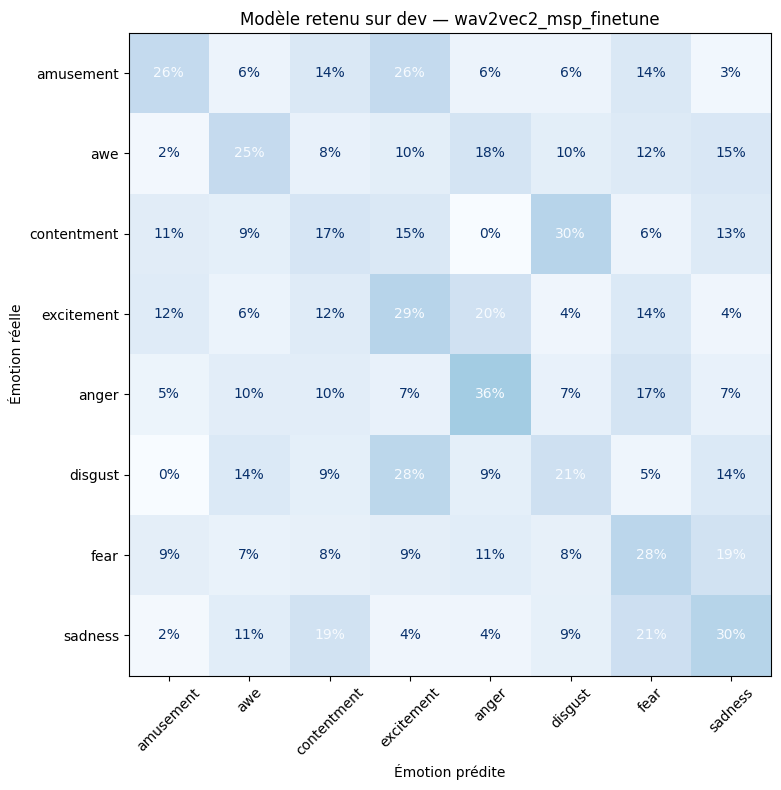

In [ ]:
predictions_dev_retenues = np.array(ordre_emotions)[probabilites_dev_retenues.argmax(axis=1)]
print(classification_report(y_dev, predictions_dev_retenues,
    labels=ordre_emotions, digits=3, zero_division=0))

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(y_dev, predictions_dev_retenues,
    labels=ordre_emotions, normalize="true", values_format=".0%", cmap="Blues",
    colorbar=False, xticks_rotation=45, im_kw={"vmin": 0, "vmax": 1}, ax=ax)
ax.set_title(f"Modèle retenu sur dev — {modele_retenu}")
ax.set_xlabel("Émotion prédite")
ax.set_ylabel("Émotion réelle")
plt.tight_layout()
plt.show()


In [ ]:
dossier_resultats = dossier_projet / "predictions_audio" / "dev_pytorch"
dossier_resultats.mkdir(parents=True, exist_ok=True)

for nom, probabilites in probabilites_modeles_dev.items():
    verifier_probabilites(probabilites, len(audio_ast_dev))

    table = pd.DataFrame(
        probabilites,
        columns=ordre_emotions,
        index=pd.Index(audio_ast_dev["video_id"], name="video_id")
    )

    table.to_csv(dossier_resultats / f"dev_{nom}.csv")

comparaison_finale.to_csv(
    dossier_resultats / "comparaison_dev_pytorch.csv",
    index=False
)

display(comparaison_finale.round(4))
print("Modèle retenu parmi les modèles comparés :", modele_retenu)
print("Résultats sauvegardés :", dossier_resultats)

,Modèle,Accuracy dev,F1 macro dev
0,wav2vec2_msp_finetune,0.2760,0.2621
1,wav2vec2_msp_initialisation,0.2738,0.2620
2,wav2vec2_msp_nn,0.2692,0.2583
3,hubert_nn,0.2443,0.2411
4,wav2vec2_msp_logistique,0.2489,0.2371
5,ast,0.2579,0.2312
6,emotion2vec_plus_large_nn,0.2466,0.2277
7,mfcc_cnn,0.2285,0.2082


Modèle retenu parmi les modèles comparés : wav2vec2_msp_finetune
Résultats sauvegardés : /content/drive/MyDrive/SID/predictions_audio/dev_pytorch


In [ ]:
dossier_predictions = dossier_projet / "predictions_audio"
dossier_torch = dossier_predictions / "dev_pytorch"
dossier_tf = dossier_predictions / "dev_tensorflow"
dossier_torch.mkdir(parents=True, exist_ok=True)

identifiants_dev = pd.Index(
    audio_ast_dev["video_id"].astype(str), name="video_id"
)
assert identifiants_dev.is_unique

# Sauvegarder les résultats de cette session.
for nom, probabilites in probabilites_modeles_dev.items():
    verifier_probabilites(probabilites, len(audio_ast_dev))
    pd.DataFrame(
        probabilites,
        index=identifiants_dev,
        columns=ordre_emotions,
    ).to_csv(dossier_torch / f"dev_{nom}.csv")

comparaison_finale.to_csv(
    dossier_torch / "comparaison_dev_pytorch.csv", index=False
)

# Ajouter les probabilités sauvegardées de la session TensorFlow.
for nom in [
    "egemaps_logistique",
    "egemaps_nn",
    "yamnet",
    "yamnet_egemaps_nn",
]:
    chemin = dossier_tf / f"dev_{nom}.csv"
    assert chemin.is_file(), f"Fichier manquant : {chemin}"

    table = pd.read_csv(
        chemin, dtype={"video_id": str}
    ).set_index("video_id")

    assert table.index.is_unique
    assert set(table.index) == set(identifiants_dev)
    assert table.columns.tolist() == ordre_emotions

    probabilites = table.loc[identifiants_dev].to_numpy()
    verifier_probabilites(probabilites, len(audio_ast_dev))
    probabilites_modeles_dev[nom] = probabilites

# Comparer tous les modèles sur les mêmes extraits.
resultats = []

for nom, probabilites in probabilites_modeles_dev.items():
    predictions = probabilites.argmax(axis=1)
    resultats.append({
        "Modèle": nom,
        "Accuracy dev": accuracy_score(
            audio_ast_dev["label"], predictions
        ),
        "F1 macro dev": f1_score(
            audio_ast_dev["label"], predictions,
            labels=np.arange(8), average="macro", zero_division=0
        ),
    })

comparaison_finale = pd.DataFrame(resultats).sort_values(
    ["F1 macro dev", "Modèle"], ascending=[False, True]
).reset_index(drop=True)

modele_retenu = comparaison_finale.iloc[0]["Modèle"]
probabilites_dev_retenues = probabilites_modeles_dev[modele_retenu]

comparaison_finale.to_csv(
    dossier_predictions / "comparaison_dev_complete.csv", index=False
)
pd.DataFrame(
    probabilites_dev_retenues,
    index=identifiants_dev,
    columns=ordre_emotions,
).to_csv(dossier_predictions / "probabilites_audio_dev.csv")

display(comparaison_finale.round(4))
print("Modèle retenu sur dev :", modele_retenu)
print("Résultats sauvegardés :", dossier_predictions)

,Modèle,Accuracy dev,F1 macro dev
0,wav2vec2_msp_finetune,0.2760,0.2621
1,wav2vec2_msp_initialisation,0.2738,0.2620
2,wav2vec2_msp_nn,0.2692,0.2583
3,hubert_nn,0.2443,0.2411
4,wav2vec2_msp_logistique,0.2489,0.2371
5,yamnet_egemaps_nn,0.2376,0.2352
6,ast,0.2579,0.2312
7,emotion2vec_plus_large_nn,0.2466,0.2277
8,yamnet,0.2149,0.2182
9,mfcc_cnn,0.2285,0.2082


Modèle retenu sur dev : wav2vec2_msp_finetune
Résultats sauvegardés : /content/drive/MyDrive/SID/predictions_audio


## 21. Évaluation finale sur test et export


In [ ]:
audio_test = donnees_audio[donnees_audio["split"] == "test"].copy()
assert len(audio_test) == 439
assert set(audio_test["film_id"]).isdisjoint(audio_apprentissage["film_id"])
assert set(audio_test["film_id"]).isdisjoint(audio_developpement["film_id"])

# Préparer les WAV temporaires nécessaires aux modèles à 16 kHz.
audio_ast_test = audio_test.reset_index(drop=True).copy()
chemins_test, nombres_test = [], []
with zipfile.ZipFile(chemin_zip, "r") as archive:
    for extrait in audio_ast_test.itertuples(index=False):
        chemin = dossier_audio_temporaire / f"{extrait.video_id}.wav"
        if not chemin.is_file():
            signal, _ = librosa.load(io.BytesIO(archive.read(extrait.chemin_audio_zip)),
                                      sr=16000, mono=True)
            sf.write(chemin, signal, 16000, subtype="FLOAT")
        infos = sf.info(chemin)
        assert infos.samplerate == 16000 and infos.channels == 1 and infos.frames > 0
        chemins_test.append(str(chemin))
        nombres_test.append(infos.frames)
audio_ast_test["chemin_audio_ast"] = chemins_test
audio_ast_test["nb_echantillons_ast"] = nombres_test
audio_ast_test["label"] = audio_ast_test["emotion"].map(emotion_vers_indice)
fenetres_test = creer_fenetres_audio(audio_ast_test)


### 21.1. Caractéristiques nécessaires au modèle retenu

Seules les caractéristiques utilisées par ce modèle sont calculées ou chargées.


In [ ]:
def caracteristiques_egemaps_test():
    chemin = dossier_caracteristiques / "egemapsv02_test_44100Hz.csv"
    if chemin.is_file():
        table = pd.read_csv(chemin, index_col="video_id")
    else:
        valeurs = []
        with zipfile.ZipFile(chemin_zip, "r") as archive:
            for extrait in audio_test.itertuples(index=False):
                signal, frequence = librosa.load(io.BytesIO(archive.read(extrait.chemin_audio_zip)),
                                                   sr=None, mono=True)
                assert frequence == frequence_exemple
                ligne = extracteur_audio.process_signal(signal, frequence).iloc[0].to_dict()
                ligne["video_id"] = extrait.video_id
                valeurs.append(ligne)
        table = pd.DataFrame(valeurs).set_index("video_id")
        table.to_csv(chemin)
    return verifier_caracteristiques(table, audio_test, X_train.columns)


if modele_retenu in ["egemaps_logistique", "egemaps_nn"]:
    X_test_final = caracteristiques_egemaps_test()
elif modele_retenu in ["yamnet", "yamnet_egemaps_nn"]:
    chemin = dossier_caracteristiques / "yamnet_v1_mean_test_16000Hz.csv"
    if chemin.is_file():
        X_test_final = pd.read_csv(chemin, index_col="video_id")
    else:
        X_test_final = extraire_caracteristiques_yamnet(audio_test)
        X_test_final.to_csv(chemin)
    X_test_final = verifier_caracteristiques(X_test_final, audio_test, colonnes_yamnet)
    if modele_retenu == "yamnet_egemaps_nn":
        X_test_final = pd.concat([X_test_final, caracteristiques_egemaps_test()], axis=1)
elif modele_retenu in ["wav2vec2_msp_logistique", "wav2vec2_msp_nn", "hubert_nn"]:
    est_hubert = modele_retenu == "hubert_nn"
    encodeur = encodeur_hubert if est_hubert else encodeur_emotion
    encodeur.to(appareil_ast).eval()
    colonnes = colonnes_hubert if est_hubert else colonnes_emotion
    nom_cache = "hubert_base_ls960" if est_hubert else "wav2vec2_msp"
    chemin = dossier_caracteristiques / f"{nom_cache}_mean10s_v1_test_16000Hz.csv"
    if chemin.is_file():
        X_test_final = pd.read_csv(chemin, index_col="video_id")
    else:
        fonction = extraire_caracteristiques_hubert if est_hubert else extraire_caracteristiques_emotion
        X_test_final = fonction(audio_ast_test)
        X_test_final.to_csv(chemin)
    X_test_final = verifier_caracteristiques(X_test_final, audio_ast_test, colonnes)
    encodeur.to("cpu")
elif modele_retenu == "emotion2vec_plus_large_nn":
    encodeur_emotion2vec.model.to(appareil_ast).eval()
    X_test_final = extraire_caracteristiques_emotion2vec(audio_ast_test, "test")
    encodeur_emotion2vec.model.to("cpu")
elif modele_retenu == "mfcc_cnn":
    mfcc_test, fenetres_mfcc_test = charger_ou_extraire_mfcc(audio_ast_test, "test")


### 21.2. Prédictions et scores sur test


In [ ]:
if modele_retenu == "egemaps_logistique":
    probabilites_test_finales = probabilites_logistique(modele_logistique, X_test_final, ordre_emotions)
elif modele_retenu in ["egemaps_nn", "yamnet", "yamnet_egemaps_nn"]:
    modeles_keras = {"egemaps_nn": (modele_nn, standardisation_nn),
                    "yamnet": (modele_yamnet_nn, standardisation_yamnet),
                    "yamnet_egemaps_nn": (modele_combine_nn, standardisation_combinee)}
    modele, scaler = modeles_keras[modele_retenu]
    probabilites_test_finales = modele.predict(scaler.transform(X_test_final).astype("float32"), verbose=0)
elif modele_retenu == "wav2vec2_msp_logistique":
    probabilites_test_finales = probabilites_logistique(modele_emotion_lineaire, X_test_final, list(range(8)))
elif modele_retenu in ["wav2vec2_msp_nn", "hubert_nn", "emotion2vec_plus_large_nn"]:
    modeles_figes = {"wav2vec2_msp_nn": (modele_emotion_nn, standardisation_emotion_nn),
                    "hubert_nn": (modele_hubert_nn, standardisation_hubert_nn),
                    "emotion2vec_plus_large_nn": (modele_emotion2vec_nn, standardisation_emotion2vec)}
    modele, scaler = modeles_figes[modele_retenu]
    valeurs = scaler.transform(X_test_final).astype("float32")
    probabilites_test_finales = probabilites_caracteristiques(modele, valeurs, audio_ast_test["label"])
elif modele_retenu == "ast":
    probabilites_test_finales = agreger_probabilites_ast(
        predire_torch(modele_ast, JeuAudioAST(fenetres_test), taille_lot=2, precision_mixte=True),
        fenetres_test, audio_ast_test)
elif modele_retenu in ["wav2vec2_msp_finetune", "wav2vec2_msp_initialisation"]:
    modele = modele_emotion_ft if modele_retenu.endswith("finetune") else modele_emotion_initial
    probabilites_test_finales = agreger_probabilites_ast(
        predire_torch(modele, JeuSignauxEmotion(fenetres_test), assembler_lot_emotion_ft,
                      taille_lot=2, precision_mixte=True), fenetres_test, audio_ast_test)
elif modele_retenu == "mfcc_cnn":
    probabilites_test_finales = agreger_probabilites_ast(
        predire_torch(modele_mfcc, JeuMFCC(mfcc_test, fenetres_mfcc_test)),
        fenetres_mfcc_test, audio_ast_test)
else:
    raise ValueError(f"Modèle non prévu : {modele_retenu}")

verifier_probabilites(probabilites_test_finales, len(audio_test))
predictions_test_finales = probabilites_test_finales.argmax(axis=1)
scores_test = {"modele": modele_retenu,
    "accuracy_test": float(accuracy_score(audio_ast_test["label"], predictions_test_finales)),
    "f1_macro_test": float(f1_score(audio_ast_test["label"], predictions_test_finales,
        labels=np.arange(8), average="macro", zero_division=0))}
print(scores_test)
print(classification_report(audio_ast_test["label"], predictions_test_finales,
    labels=np.arange(8), target_names=ordre_emotions, digits=3, zero_division=0))


{'modele': 'wav2vec2_msp_finetune', 'accuracy_test': 0.24145785876993167, 'f1_macro_test': 0.2197789350151856}
              precision    recall  f1-score   support

   amusement      0.152     0.200     0.173        35
         awe      0.154     0.100     0.121        40
 contentment      0.208     0.185     0.196        54
  excitement      0.176     0.255     0.208        51
       anger      0.456     0.323     0.378        96
     disgust      0.149     0.163     0.156        43
        fear      0.311     0.311     0.311        74
     sadness      0.196     0.239     0.216        46

    accuracy                          0.241       439
   macro avg      0.225     0.222     0.220       439
weighted avg      0.259     0.241     0.246       439



Sur les 439 extraits de test, le modèle obtient une accuracy de 24,15 % et un F1 macro de 0,2198, contre 0,2621 sur dev. Les résultats restent modestes. La colère et la peur sont les émotions les mieux reconnues, tandis que l’émerveillement est plus difficile à identifier.

### 21.3. Export pour la fusion

Nous enregistrons un identifiant et huit probabilités par extrait, dans le même
ordre pour dev et test. Les autres branches pourront les joindre par 'video_id'.
La fusion avec le texte et la vidéo sera réalisée séparément.


In [ ]:
dossier_predictions = dossier_projet / "predictions_audio"
dossier_predictions.mkdir(parents=True, exist_ok=True)

for ensemble, table, probabilites in [
    ("dev", audio_ast_dev, probabilites_dev_retenues),
    ("test", audio_ast_test, probabilites_test_finales)
]:
    export = pd.DataFrame(probabilites, columns=ordre_emotions,
        index=pd.Index(table["video_id"], name="video_id"))
    assert export.index.is_unique
    export.to_csv(dossier_predictions / f"probabilites_audio_{ensemble}.csv")

parametres_export = {"modele_retenu": modele_retenu, "ordre_emotions": ordre_emotions,
    "critere_choix": "F1 macro dev", "f1_macro_dev": float(comparaison_finale.iloc[0]["F1 macro dev"]),
    "nombre_extraits_dev": len(audio_ast_dev), "nombre_extraits_test": len(audio_ast_test),
    "scores_test": scores_test}
(dossier_predictions / "modele_retenu.json").write_text(
    json.dumps(parametres_export, ensure_ascii=False, indent=2), encoding="utf-8")
print("Exports enregistrés :", dossier_predictions)


Exports enregistrés : /content/drive/MyDrive/SID/predictions_audio


### 21.4. Téléchargement du modèle.

In [ ]:
from google.colab import files

chemin_modele = fichier_poids(sauvegarde_emotion_ft)
assert chemin_modele is not None

files.download(str(chemin_modele))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json
import shutil
from pathlib import Path
from importlib.metadata import version
from google.colab import files

dossier = Path("/content/configuration_audio")
dossier.mkdir(parents=True, exist_ok=True)

modele_emotion_ft.encodeur.config.save_pretrained(str(dossier))
extracteur_emotion.save_pretrained(str(dossier))

(dossier / "parametres.json").write_text(
    json.dumps({
        "ordre_emotions": list(ordre_emotions),
        "frequence": 16000,
        "duree_fenetre": 10,
    }, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

(dossier / "requirements.txt").write_text(
    f"transformers=={version('transformers')}\n"
    "torch\nsafetensors\nlibrosa\nnumpy\n",
    encoding="utf-8"
)

archive = shutil.make_archive(
    "/content/configuration_audio", "zip", root_dir=dossier
)
files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>